# fsaverage cohort-level QC

This notebook displays the Python-generated cohort QC for the common 30-subject fsaverage cohort. It does not regenerate profiles or perform vertex mapping.

The formal analysis mask is the fsaverage cortex label intersected with non-excluded DK annotation labels. A vertex profile is valid only when all 21 MD values are finite and nonzero, all 21 sampling points are in bounds, the mapping is valid, and the white-to-pial line has nonzero length.

The spatial QC includes mixed-label frequency, zero-length frequency, out-of-bounds frequency, invalid-profile frequency, and mixed-label distance to the nearest DK boundary. Out-of-bounds is the MD-volume boundary/FOV proxy; the MGH overlays remain available for Freeview inspection.

Depth orientation in these cached outputs is provisional: depth 0.00 corresponds to the white surface and depth 1.00 to the pial surface. This notebook does not alter the cached profiles; the final standard depth convention will be set in the regenerated implementation.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
from IPython.display import Image, display

OUTPUT_ROOT = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/results/"
    "o3_cohort_qc_fsaverage"
)
TABLE_ROOT = OUTPUT_ROOT / "tables"
FIGURE_ROOT = OUTPUT_ROOT / "figures"
O3_ROOT = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/results/"
    "o3_coordinate_profiles"
)
FS_SUBJECTS_DIR = Path("/home/apps/freesurfer/subjects")
REPO_ROOT = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/code/"
    "cortical_trajectory_analysis"
)
MANIFEST_PATH = REPO_ROOT / "manifests/method_comparison_common_30_subjects.csv"
manifest = pd.read_csv(MANIFEST_PATH)
vertex_frequency = pd.read_csv(
    TABLE_ROOT / "cohort_vertex_frequency.csv"
)
metadata = json.loads((OUTPUT_ROOT / "run_metadata.json").read_text())
print("Subjects:", metadata["n_subjects"])
print("Template:", metadata["template"])
print("Tables are saved under:", TABLE_ROOT)

Subjects: 30
Template: fsaverage
Tables are saved under: /mnt/newStor/paros/paros_WORK/xintong/results/o3_cohort_qc_fsaverage/tables


## 1. Profile coverage and geometry

These figures show complete-profile coverage and zero-length geometry. Coverage is pooled across hemispheres within each subject using vertex-count weighting.

01_valid_profile_coverage.png


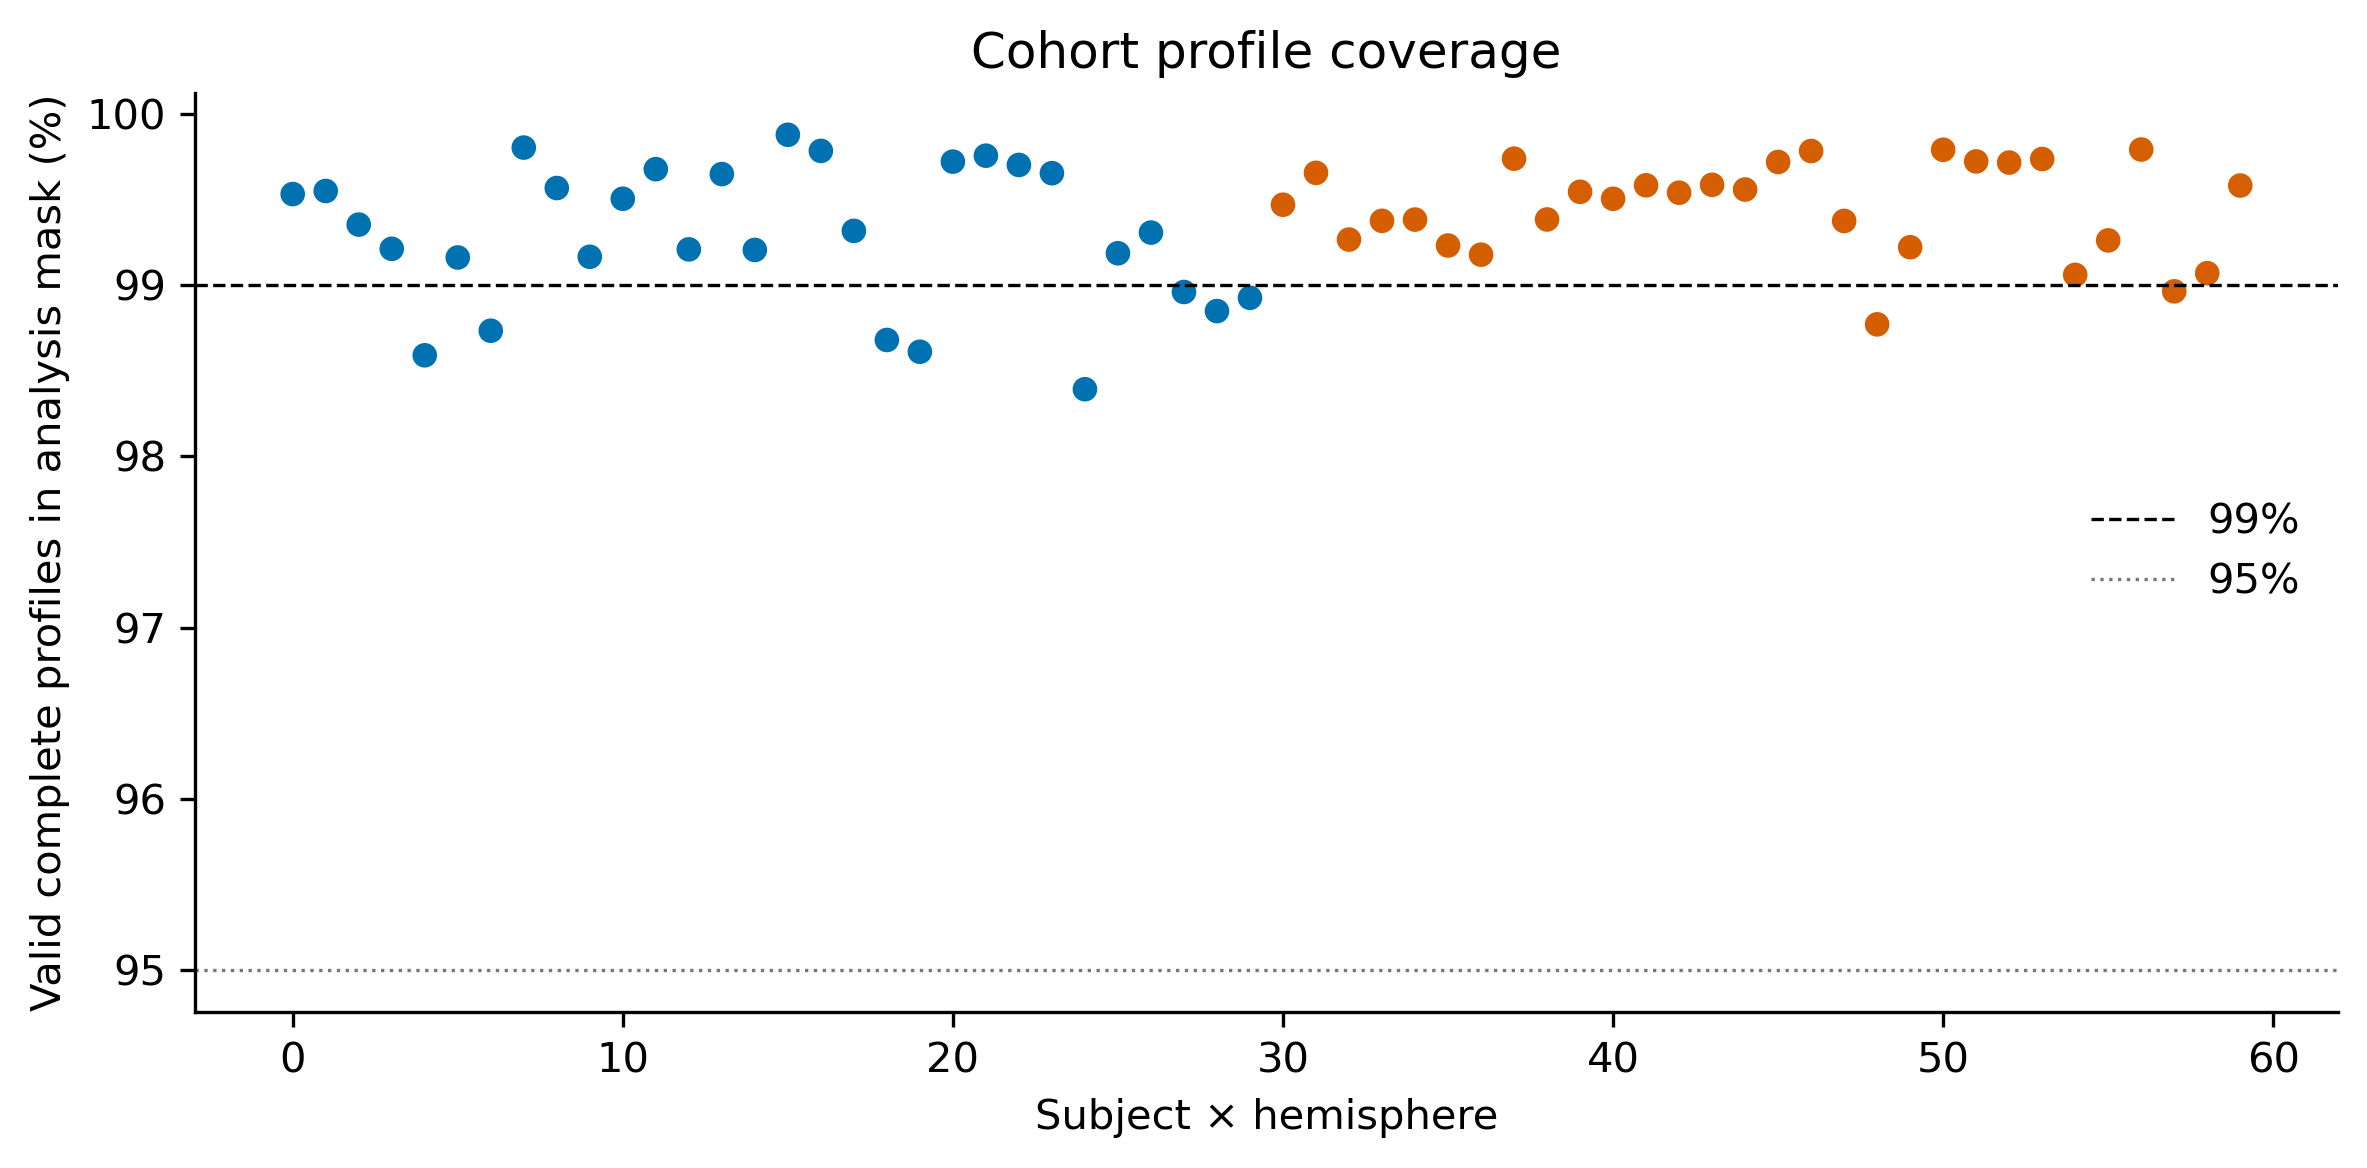

02_zero_length_full_mesh_vs_mask.png


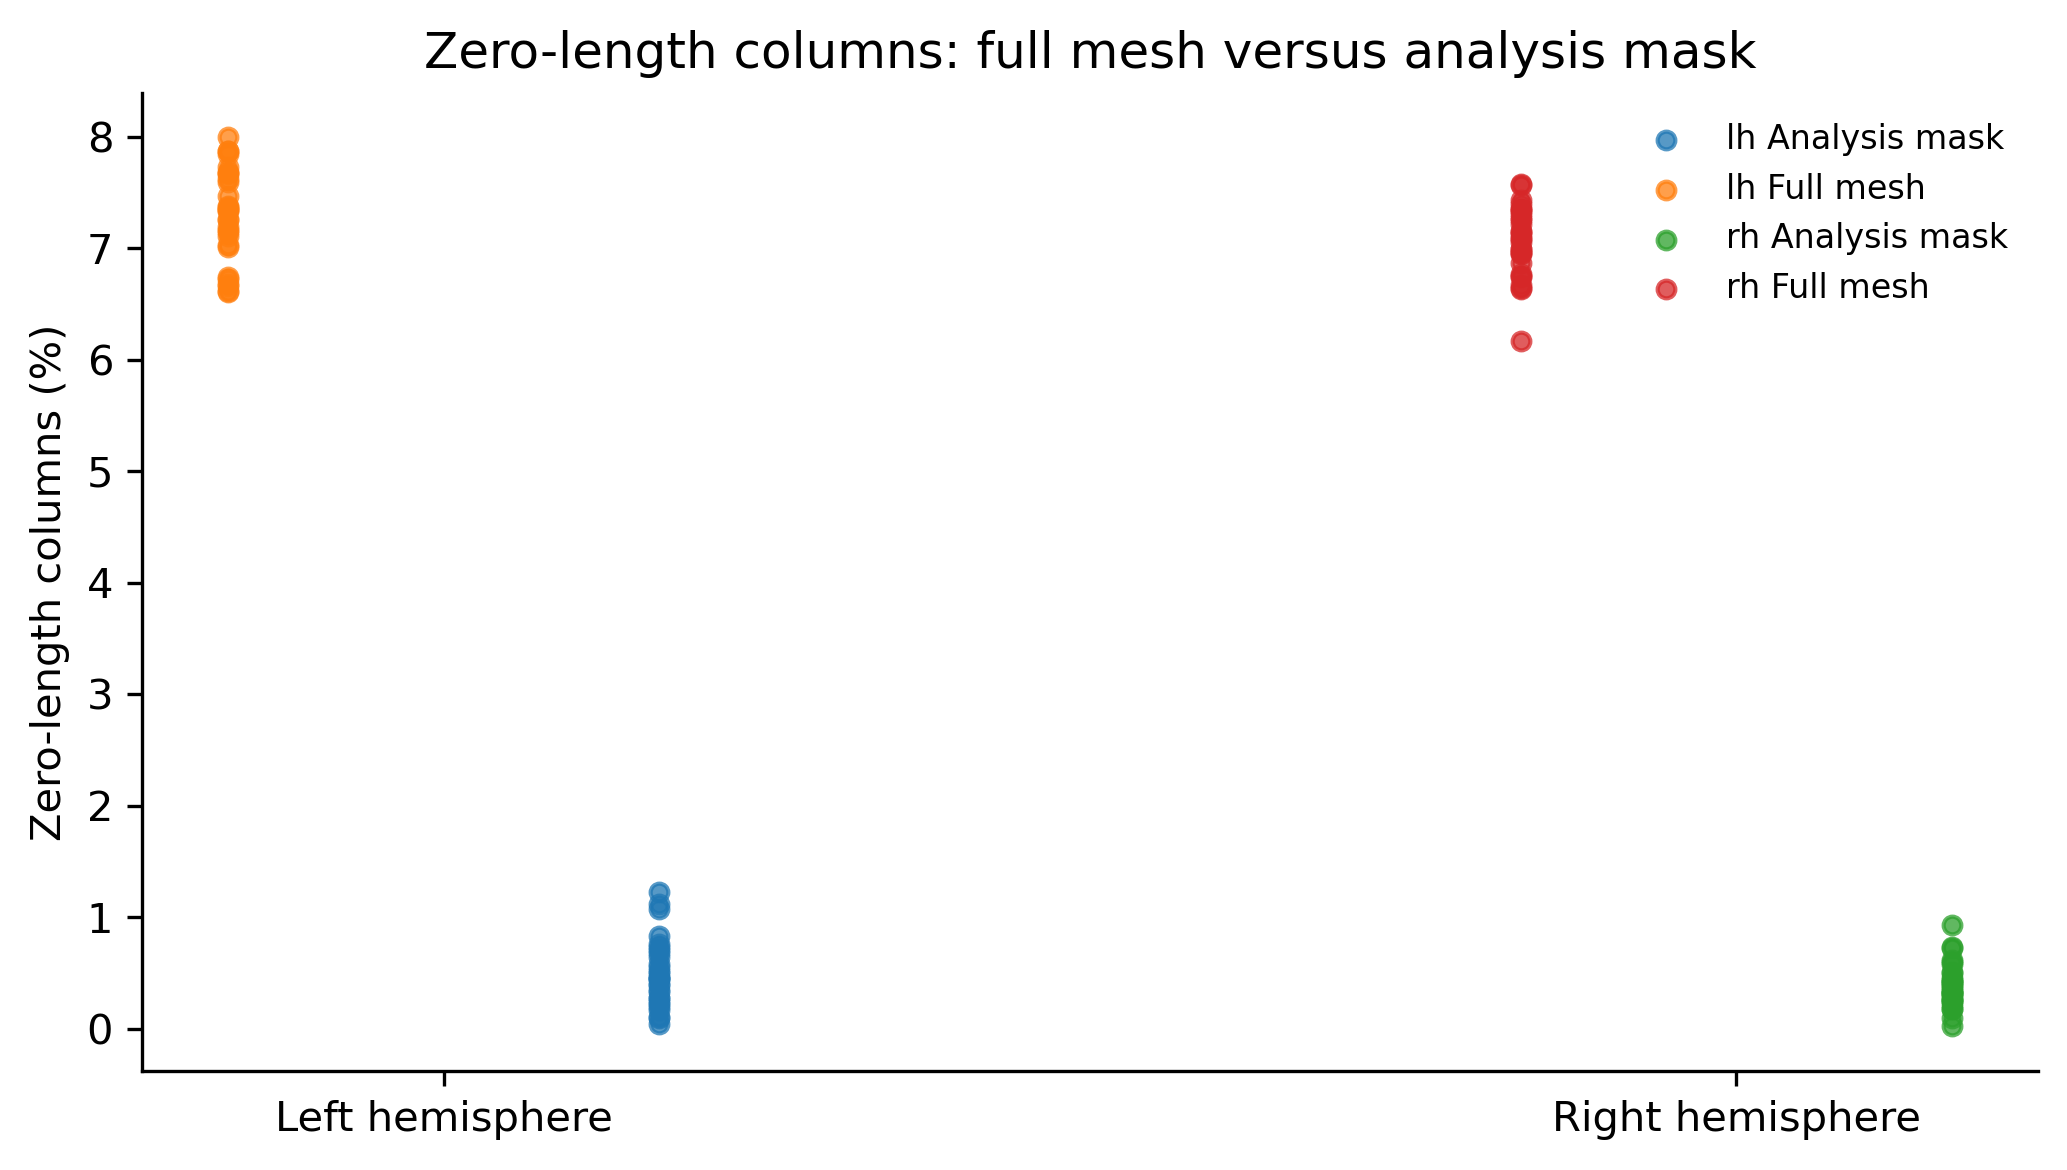

08a_hemisphere_pooled_profile_coverage.png


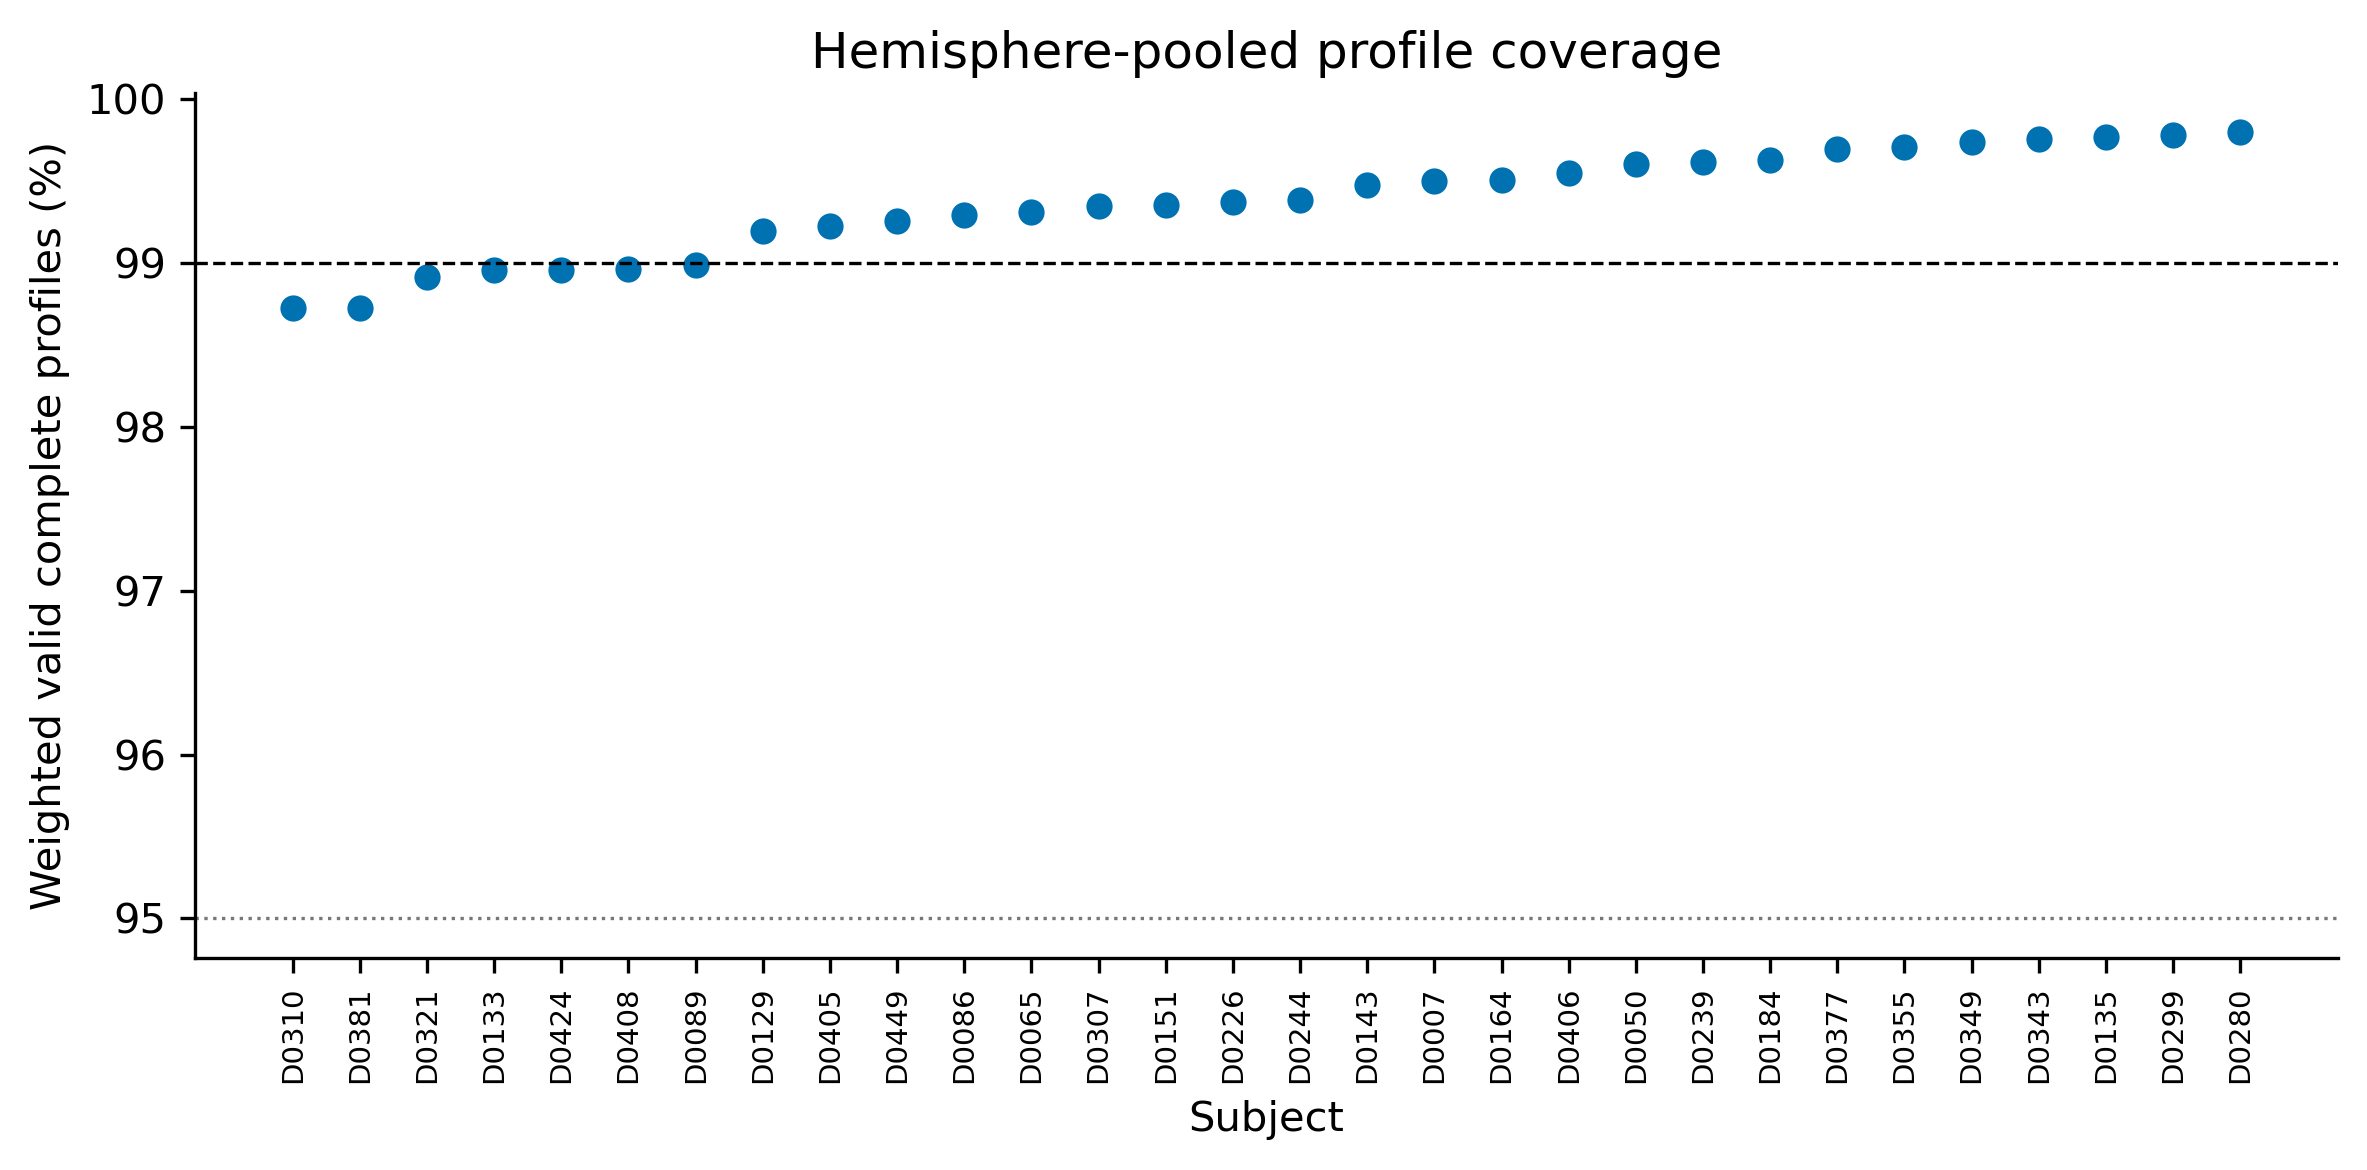

08b_zero_length_full_mesh_vs_mask.png


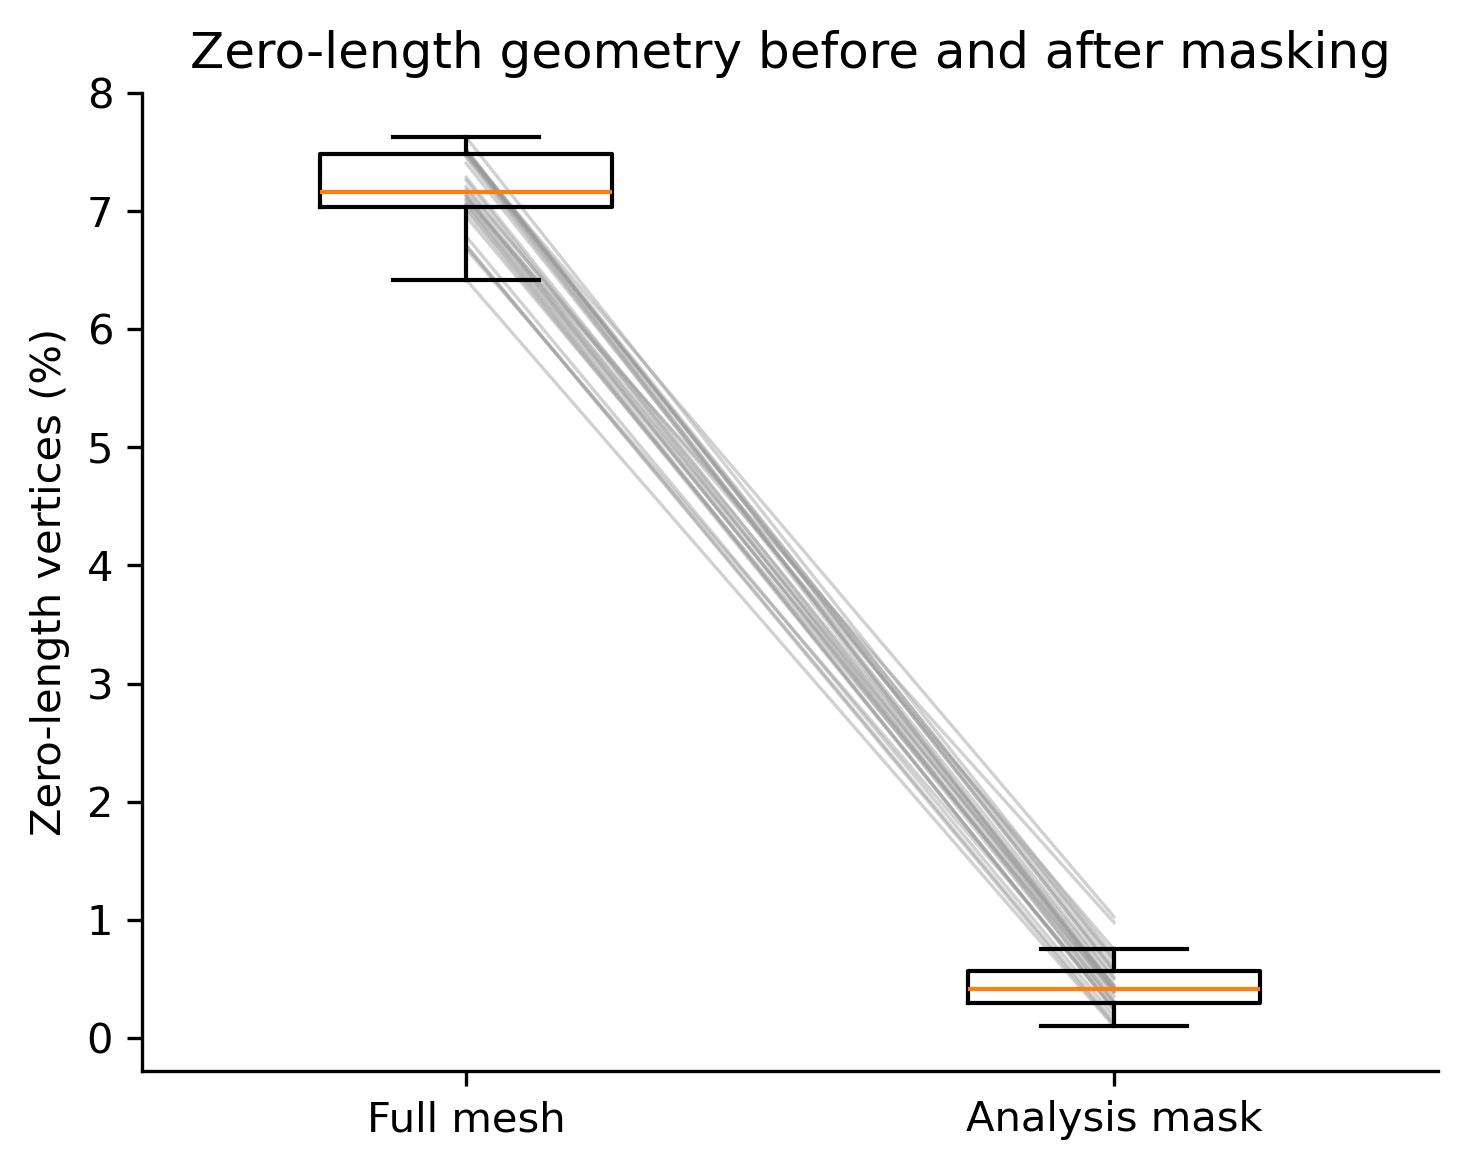

In [2]:
for figure_name in [
    "01_valid_profile_coverage.png",
    "02_zero_length_full_mesh_vs_mask.png",
    "08a_hemisphere_pooled_profile_coverage.png",
    "08b_zero_length_full_mesh_vs_mask.png",
]:
    print(figure_name)
    display(Image(filename=str(FIGURE_ROOT / figure_name)))

## 2. MD sampling validity

These figures show out-of-bounds, zero-MD, and NaN/Inf sampling across cortical depth. Out-of-bounds is evaluated against the valid MD-volume index range.

03_out_of_bounds_vertex_and_depth.png


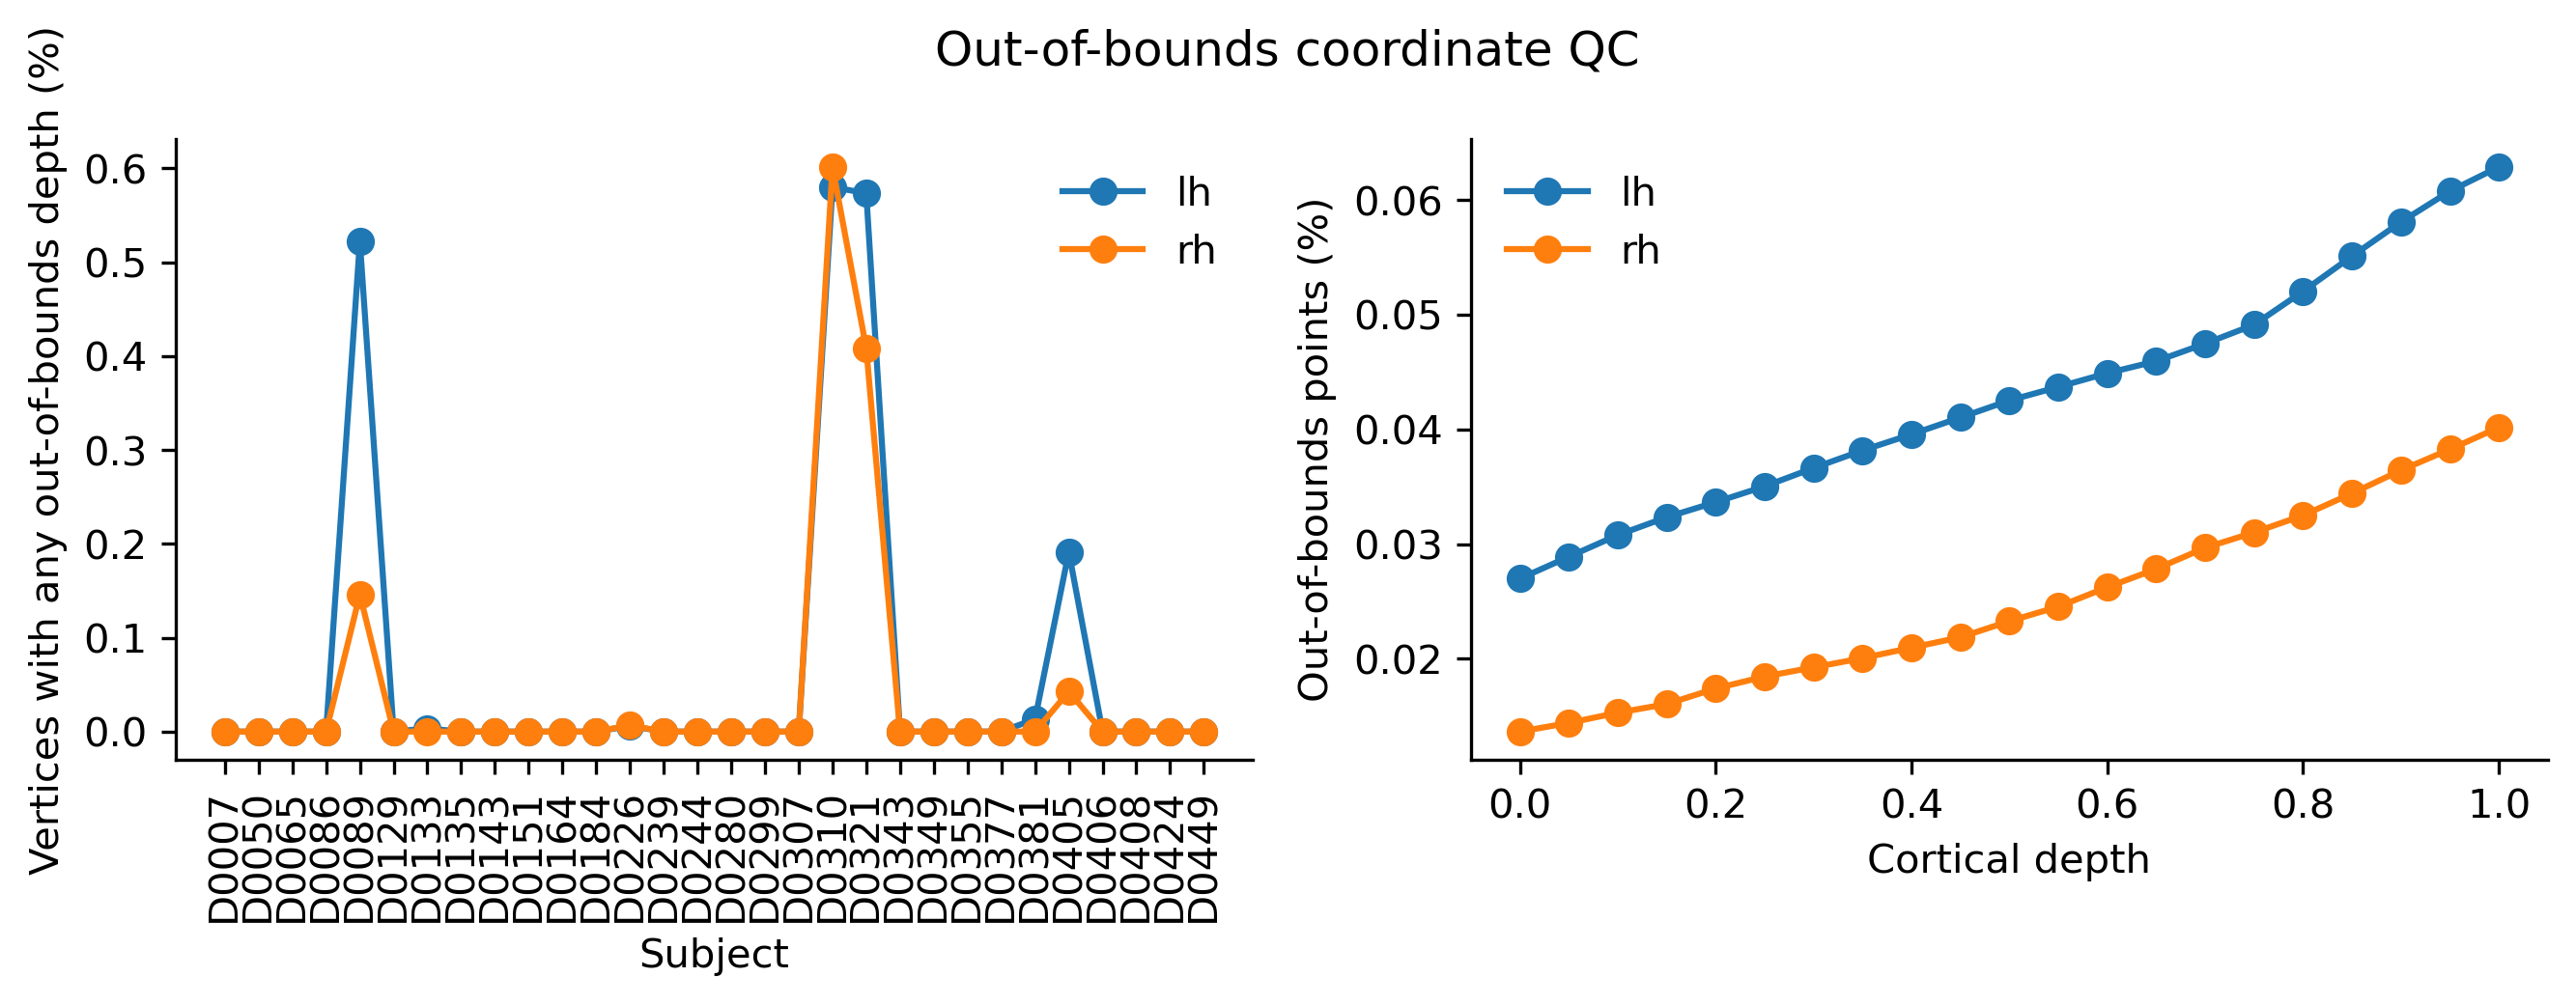

08c_invalid_md_sampling_by_depth.png


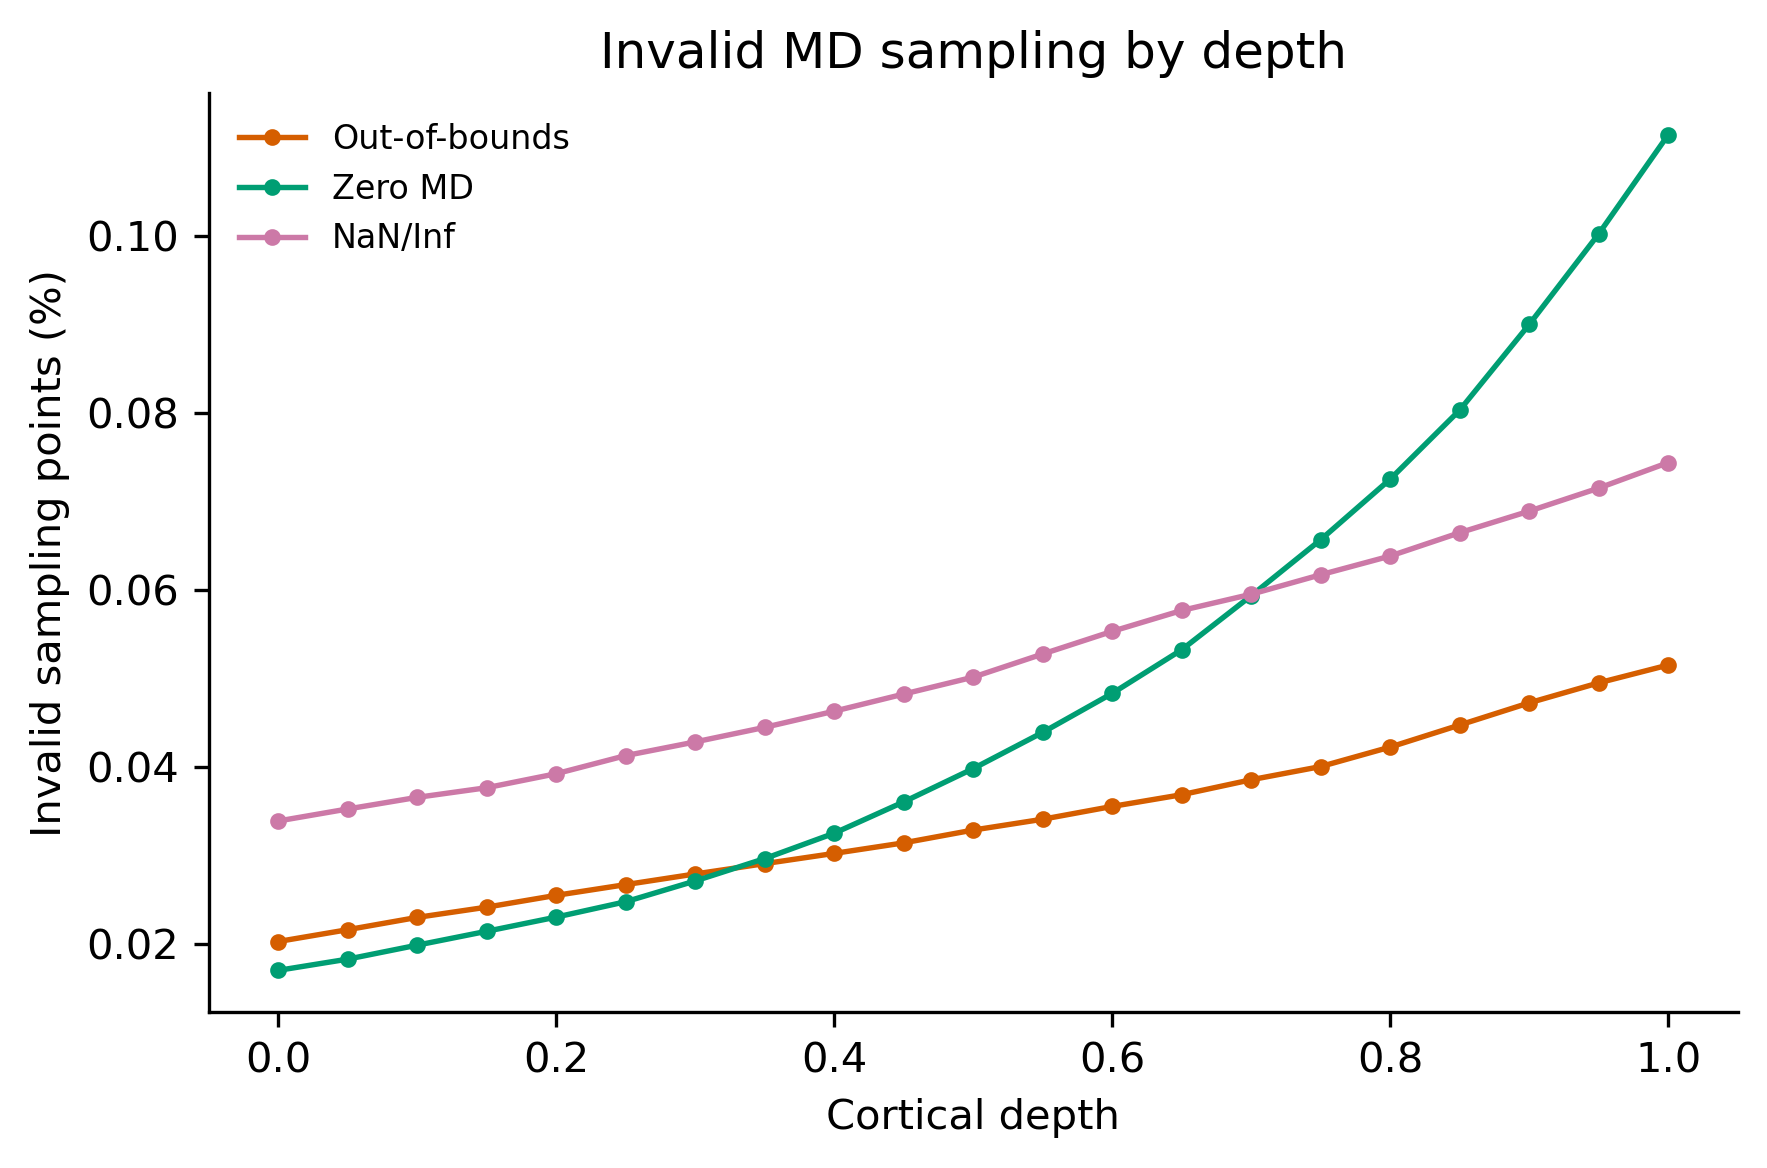

In [3]:
for figure_name in [
    "03_out_of_bounds_vertex_and_depth.png",
    "08c_invalid_md_sampling_by_depth.png",
]:
    print(figure_name)
    display(Image(filename=str(FIGURE_ROOT / figure_name)))

## 3. Column length and FreeSurfer thickness

This section checks whether interpolated white-to-pial column length agrees with native FreeSurfer cortical thickness.

04_column_length_and_thickness.png


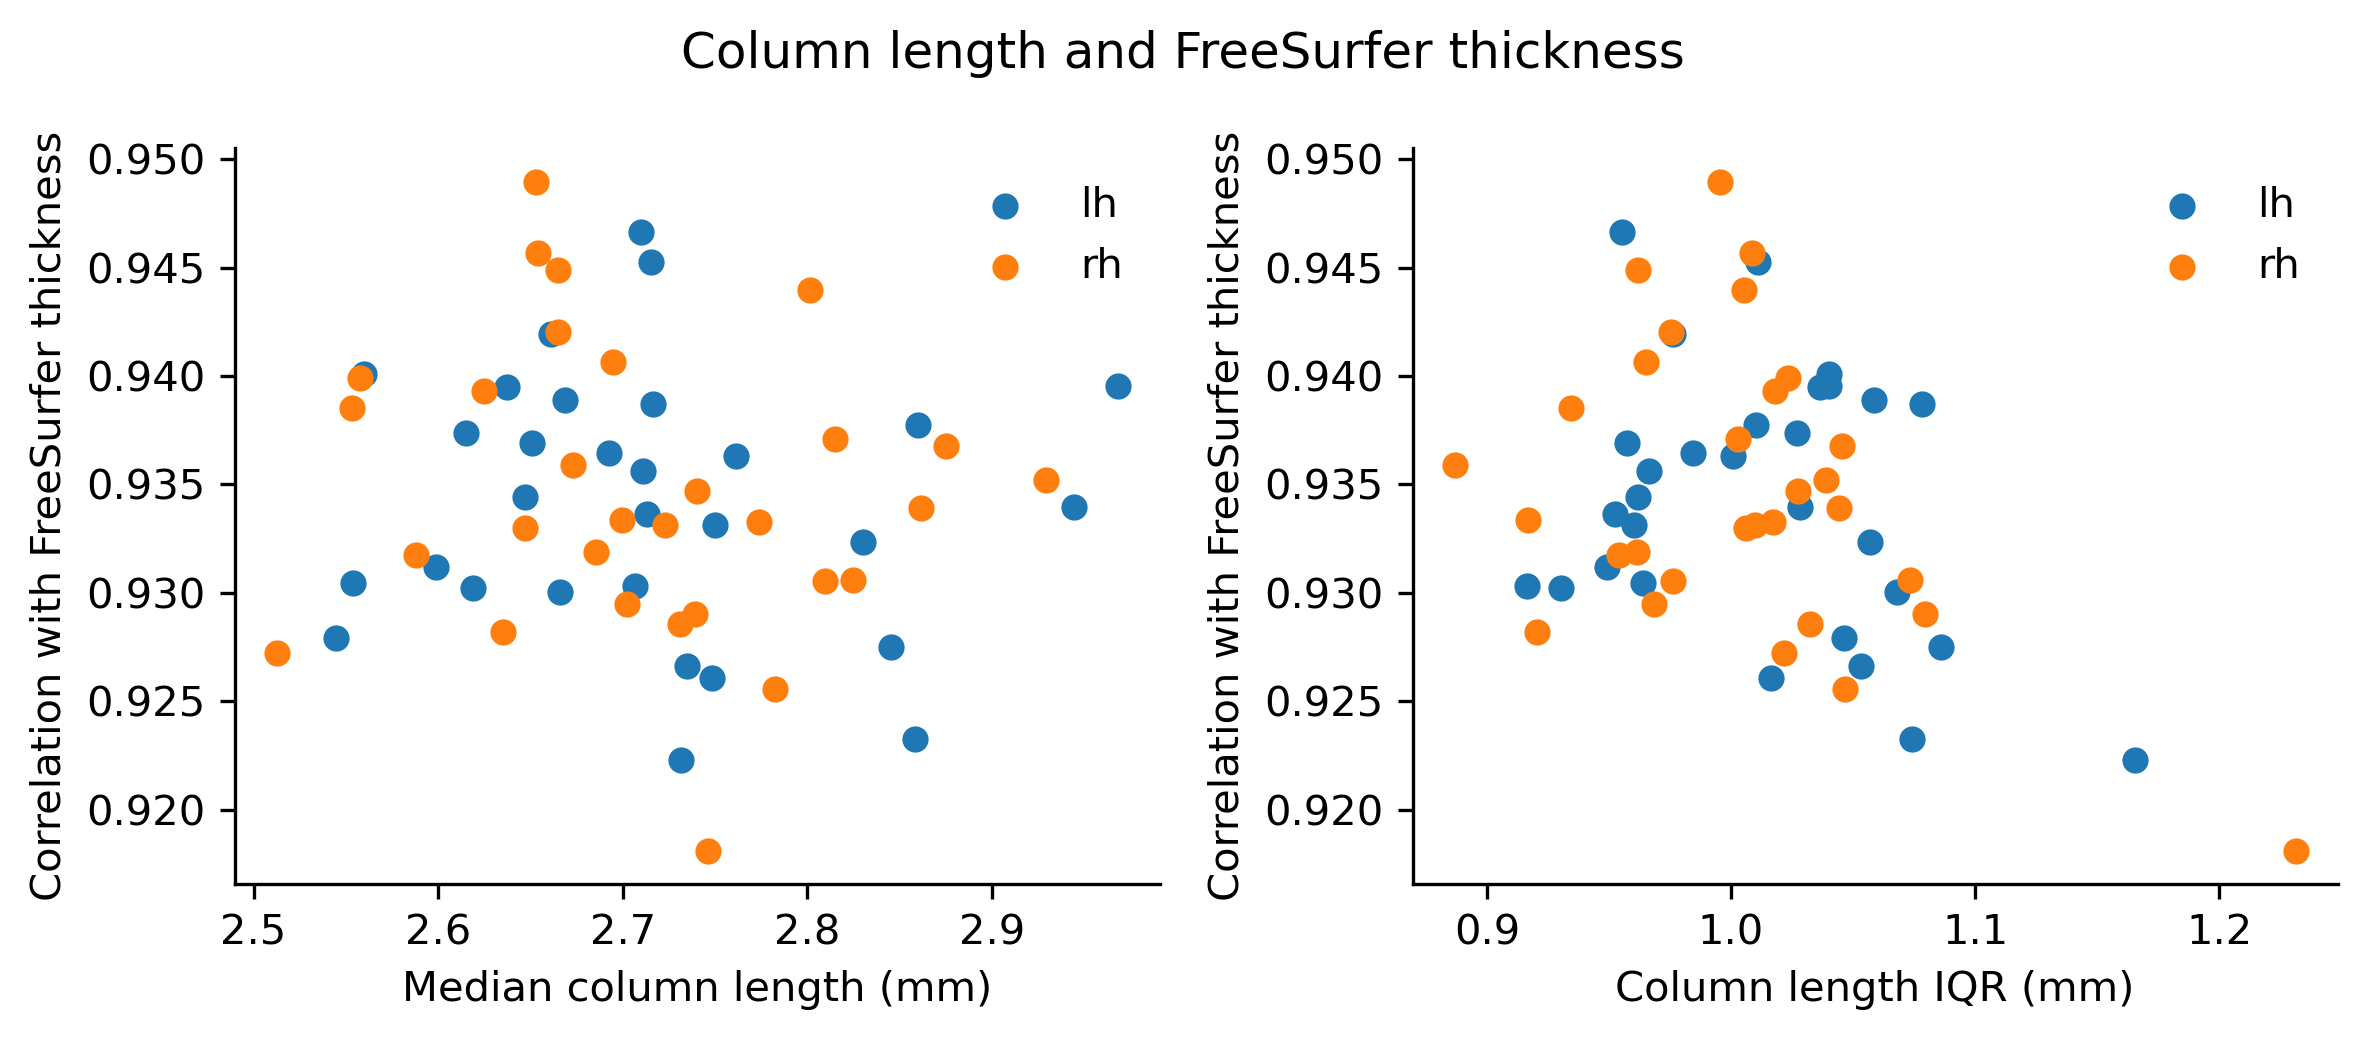

08d_length_thickness_correlation.png


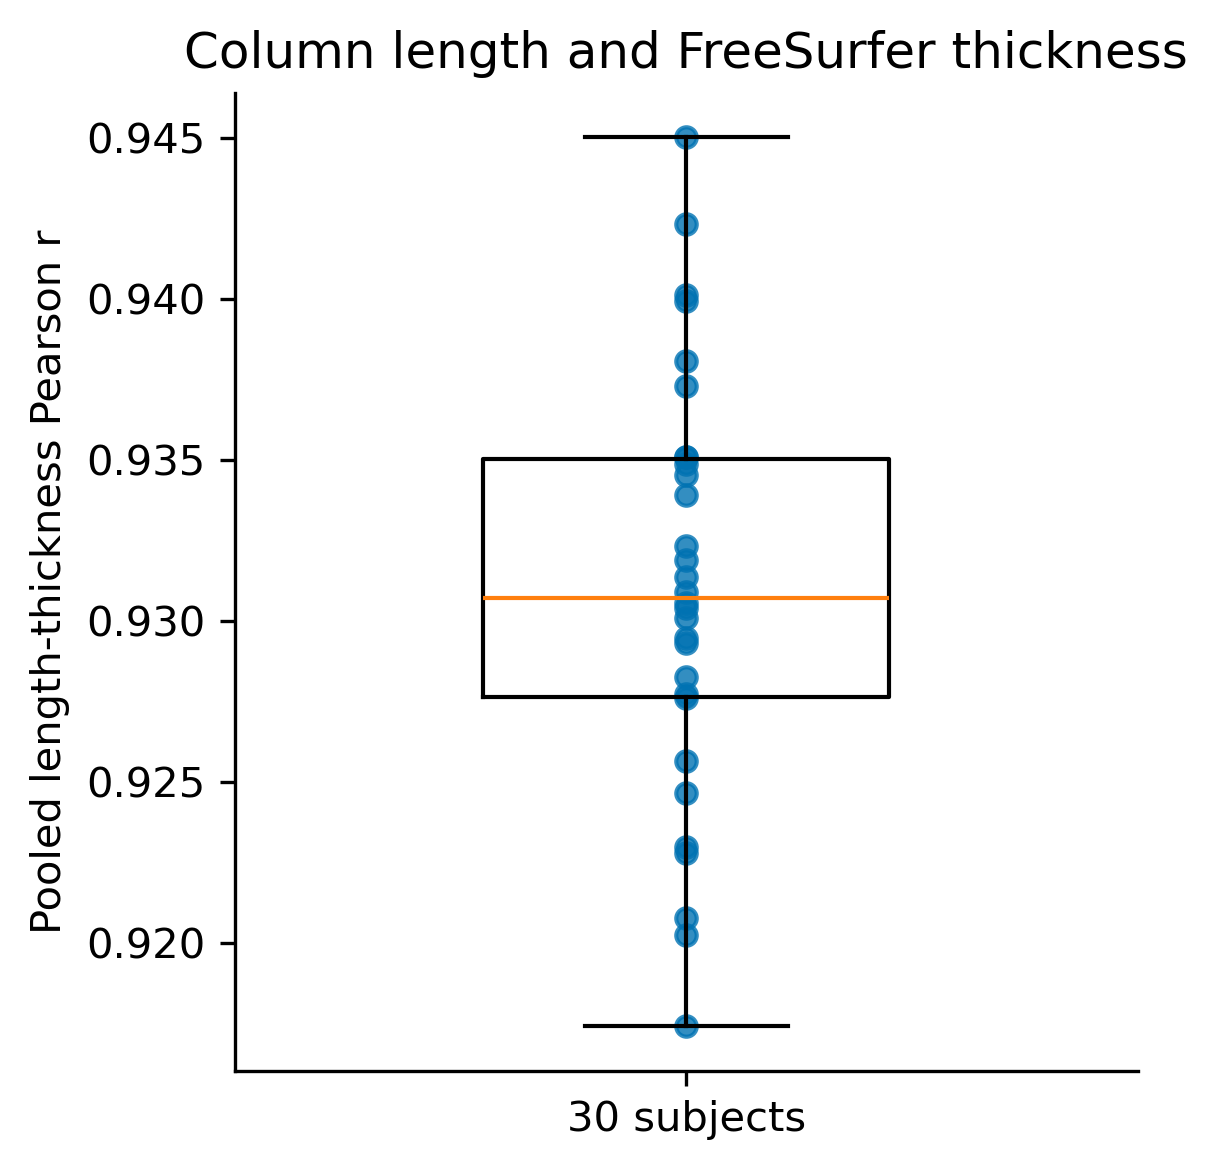

In [4]:
for figure_name in [
    "04_column_length_and_thickness.png",
    "08d_length_thickness_correlation.png",
]:
    print(figure_name)
    display(Image(filename=str(FIGURE_ROOT / figure_name)))

## 4. Label and spatial mapping QC

This section checks whether mixed labels and invalid locations are concentrated near DK region boundaries, medial-wall-adjacent areas, or the MD-volume field-of-view boundary. Surface maps are shown on the fsaverage inflated cortical surface and restricted to the analysis mask.

Label QC consists of vertex-index and file correspondence, triangle label validity, native-label composition and template-label support, and visual inspection of normal and mixed-label cases. Labels are treated as categorical values; no label IDs are numerically interpolated.

07_mixed_label_distance_to_dk_boundary.png


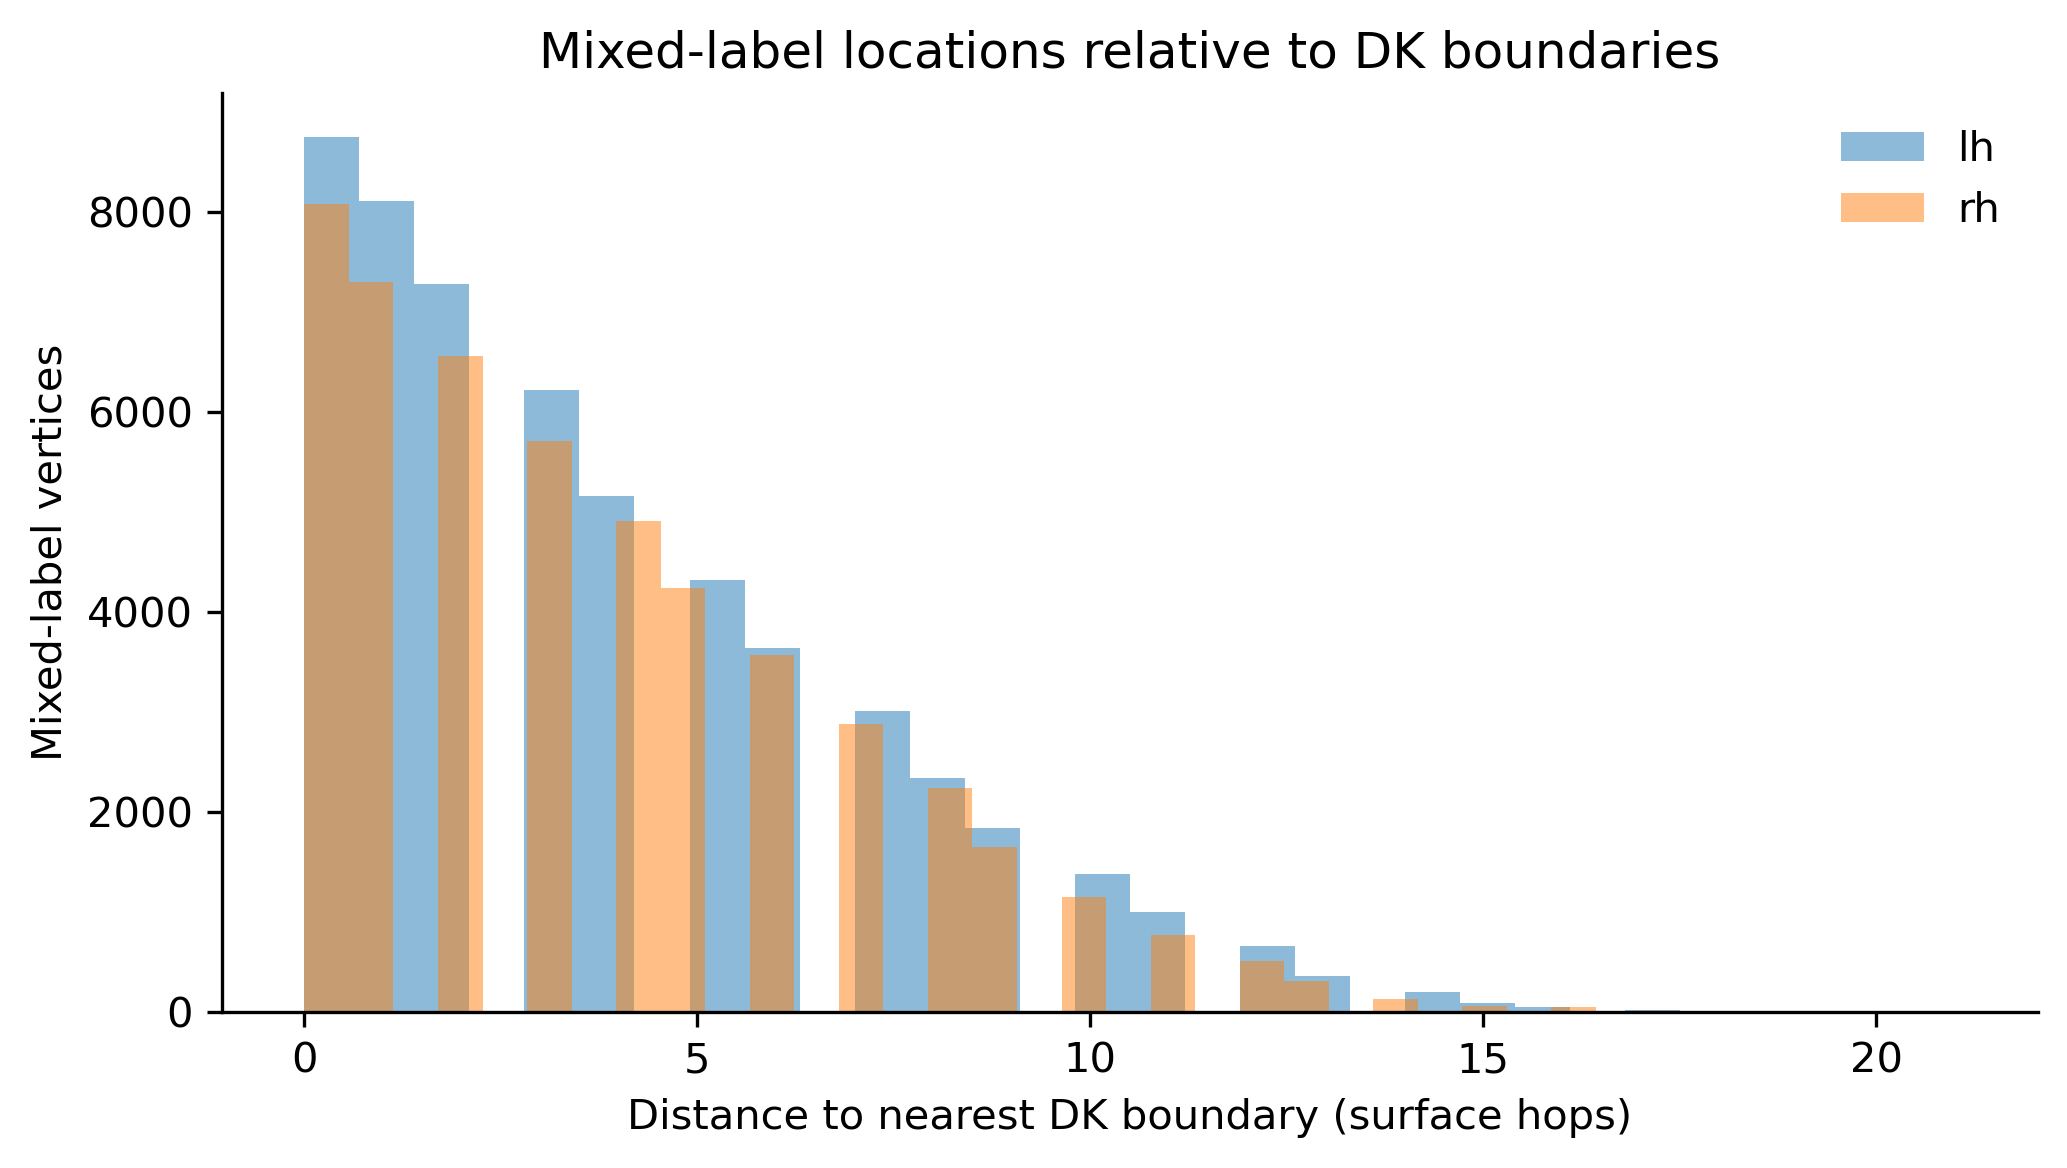

09_spatial_frequency_maps.png


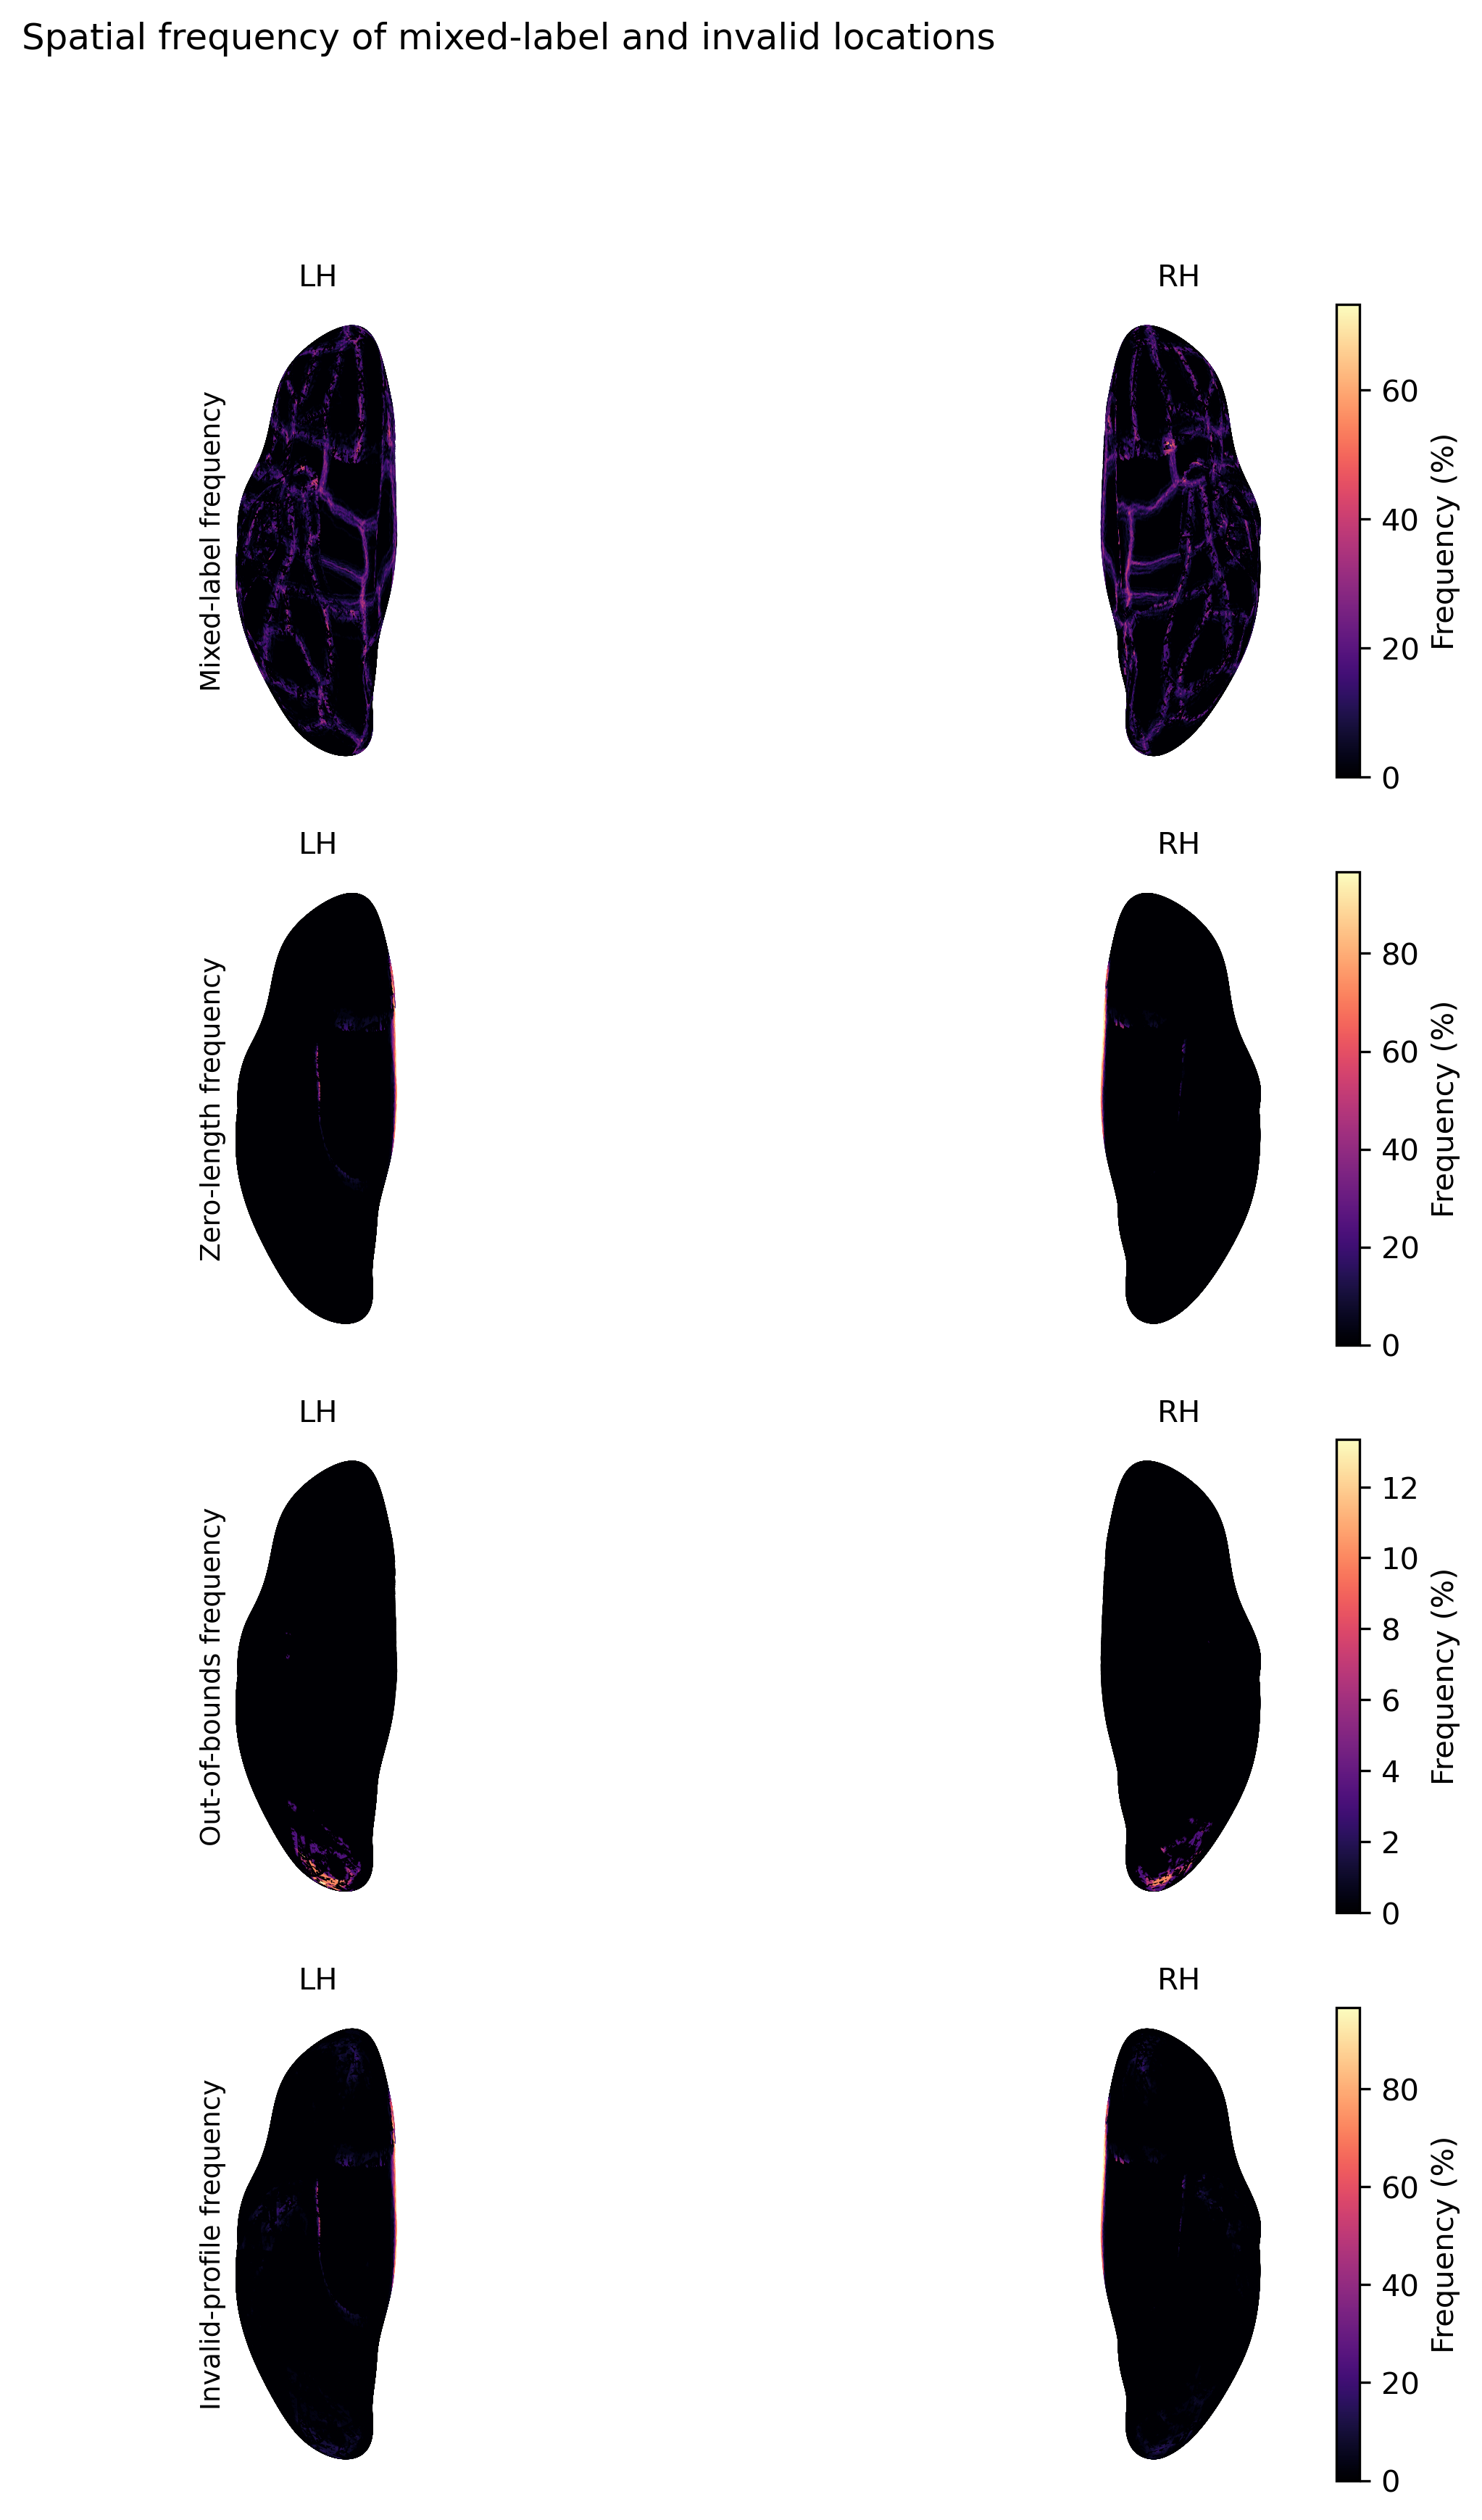

In [5]:
for figure_name in [
    "07_mixed_label_distance_to_dk_boundary.png",
    "09_spatial_frequency_maps.png",
]:
    print(figure_name)
    display(Image(filename=str(FIGURE_ROOT / figure_name)))

In [6]:
EXCLUDED_LABELS = {
    "unknown",
    "corpuscallosum",
    "medial_wall",
    "medialwall",
}


def decode_annotation_names(names):
    return [
        name.decode() if isinstance(name, bytes) else str(name)
        for name in names
    ]


def load_analysis_mask(annotation_path, cortex_path):
    labels, _, names = nib.freesurfer.io.read_annot(
        str(annotation_path)
    )
    names = decode_annotation_names(names)
    cortical_codes = np.array(
        [
            code
            for code, name in enumerate(names)
            if name.lower().replace("-", "_") not in EXCLUDED_LABELS
        ],
        dtype=np.int64,
    )
    cortex_vertices = np.asarray(
        nib.freesurfer.io.read_label(str(cortex_path))
    )
    if cortex_vertices.ndim > 1:
        cortex_vertices = cortex_vertices[:, 0]
    cortex_mask = np.zeros(len(labels), dtype=bool)
    cortex_mask[cortex_vertices.astype(int)] = True
    return labels.astype(np.int64), names, cortex_mask & np.isin(
        labels, cortical_codes
    )


boundary_lookup = {
    hemisphere: vertex_frequency[
        vertex_frequency.hemisphere.eq(hemisphere)
    ].sort_values("vertex_id").dk_boundary_hops.to_numpy()
    for hemisphere in ["lh", "rh"]
}
label_rows = []
boundary_rows = []
support_arrays = []
correspondence_rows = []
case_rows = []

for manifest_row in manifest.itertuples(index=False):
    subject = str(manifest_row.subject_id)
    native_root = Path(manifest_row.subjects_dir) / subject
    for hemisphere in ["lh", "rh"]:
        profile_path = (
            O3_ROOT
            / subject
            / "fsaverage"
            / "o3_coordinate"
            / f"{subject}_{hemisphere}_profiles.npz"
        )
        if not profile_path.exists():
            continue
        with np.load(profile_path, allow_pickle=True) as data:
            bundle = {key: data[key] for key in data.files}
        order = np.argsort(bundle["target_vertex_id"])
        target_ids = np.asarray(
            bundle["target_vertex_id"]
        )[order].astype(int)
        source_face_id = np.asarray(
            bundle["source_face_id"]
        )[order].astype(int)
        source_ids = np.asarray(
            bundle["source_vertex_ids"]
        )[order].astype(int)
        weights = np.asarray(
            bundle["barycentric_weights"]
        )[order].astype(float)
        mapping_valid = np.asarray(bundle["mapping_valid"])[order].astype(bool)

        surface_root = native_root / "surf"
        sphere, faces = nib.freesurfer.io.read_geometry(
            str(surface_root / f"{hemisphere}.sphere.reg")
        )
        white, _ = nib.freesurfer.io.read_geometry(
            str(surface_root / f"{hemisphere}.white")
        )
        pial, _ = nib.freesurfer.io.read_geometry(
            str(surface_root / f"{hemisphere}.pial")
        )
        native_labels, native_names, _ = load_analysis_mask(
            native_root / "label" / f"{hemisphere}.aparc.annot",
            native_root / "label" / f"{hemisphere}.cortex.label",
        )
        template_labels, _, template_mask = load_analysis_mask(
            FS_SUBJECTS_DIR
            / "fsaverage"
            / "label"
            / f"{hemisphere}.aparc.annot",
            FS_SUBJECTS_DIR
            / "fsaverage"
            / "label"
            / f"{hemisphere}.cortex.label",
        )
        source_ids_valid = np.all(
            (source_ids >= 0) & (source_ids < len(sphere)),
            axis=1,
        )
        face_ids_valid = (source_face_id >= 0) & (source_face_id < len(faces))
        face_vertex_match = np.zeros(len(target_ids), dtype=bool)
        valid_rows = face_ids_valid & source_ids_valid
        face_vertex_match[valid_rows] = np.all(
            faces[source_face_id[valid_rows]] == source_ids[valid_rows],
            axis=1,
        )
        weight_valid = (
            np.isfinite(weights).all(axis=1)
            & (np.abs(weights.sum(axis=1) - 1.0) <= 1e-6)
            & (weights >= -1e-6).all(axis=1)
            & (weights <= 1.0 + 1e-6).all(axis=1)
        )
        strict_mapping = (
            mapping_valid
            & face_ids_valid
            & source_ids_valid
            & face_vertex_match
            & weight_valid
        )
        source_label_values = np.full(source_ids.shape, -1, dtype=int)
        source_label_values[source_ids_valid] = native_labels[
            source_ids[source_ids_valid]
        ]
        native_valid_code = np.array(
            [
                name.lower().replace("-", "_") not in EXCLUDED_LABELS
                for name in native_names
            ],
            dtype=bool,
        )
        all_source_labels_valid = np.zeros(len(target_ids), dtype=bool)
        all_source_labels_valid[strict_mapping] = native_valid_code[
            source_label_values[strict_mapping]
        ].all(axis=1)
        mixed_valid_labels = all_source_labels_valid & (
            (source_label_values[:, 0] != source_label_values[:, 1])
            | (source_label_values[:, 1] != source_label_values[:, 2])
        )
        noncortical_source = strict_mapping & ~all_source_labels_valid
        template_label = template_labels[target_ids]
        template_support = np.full(len(target_ids), np.nan, dtype=float)
        template_support[strict_mapping] = (
            weights[strict_mapping]
            * (source_label_values[strict_mapping] == template_label[strict_mapping, None])
        ).sum(axis=1)
        in_analysis_mask = template_mask[target_ids]
        support_keep = strict_mapping & all_source_labels_valid & in_analysis_mask
        support_arrays.append(template_support[support_keep])
        hops = boundary_lookup[hemisphere][target_ids]
        for hop in np.unique(hops[in_analysis_mask & np.isfinite(hops)]):
            keep = in_analysis_mask & (hops == hop) & all_source_labels_valid
            boundary_rows.append(
                {
                    "subject": subject,
                    "hemisphere": hemisphere,
                    "boundary_hops": float(hop),
                    "n_valid_label_triangles": int(keep.sum()),
                    "n_mixed_valid_label_triangles": int((keep & mixed_valid_labels).sum()),
                    "mixed_valid_label_pct": (
                        (keep & mixed_valid_labels).sum() / keep.sum() * 100
                        if keep.sum() else np.nan
                    ),
                }
            )
        analysis_count = int(in_analysis_mask.sum())
        label_rows.append(
            {
                "subject": subject,
                "hemisphere": hemisphere,
                "n_template_vertices": len(target_ids),
                "n_analysis_mask": analysis_count,
                "n_strict_mapping": int((strict_mapping & in_analysis_mask).sum()),
                "n_valid_label_triangles": int((all_source_labels_valid & in_analysis_mask).sum()),
                "n_mixed_valid_label_triangles": int((mixed_valid_labels & in_analysis_mask).sum()),
                "n_noncortical_unknown_triangles": int((noncortical_source & in_analysis_mask).sum()),
                "valid_label_triangle_pct": all_source_labels_valid[in_analysis_mask].mean() * 100,
                "mixed_valid_label_pct": mixed_valid_labels[in_analysis_mask].mean() * 100,
                "noncortical_unknown_pct": noncortical_source[in_analysis_mask].mean() * 100,
                "template_support_median": np.nanmedian(template_support[support_keep]),
                "template_support_p01": np.nanpercentile(template_support[support_keep], 1),
                "template_support_p99": np.nanpercentile(template_support[support_keep], 99),
            }
        )
        correspondence_rows.append(
            {
                "subject": subject,
                "hemisphere": hemisphere,
                "n_label_vertices": len(native_labels),
                "n_white_vertices": len(white),
                "n_pial_vertices": len(pial),
                "n_sphere_reg_vertices": len(sphere),
                "all_surface_lengths_match": len({len(native_labels), len(white), len(pial), len(sphere)}) == 1,
                "n_face_vertex_mismatches": int((valid_rows & ~face_vertex_match).sum()),
                "n_out_of_range_source_ids": int((~source_ids_valid).sum()),
                "n_out_of_range_face_ids": int((~face_ids_valid).sum()),
            }
        )
        case_rows.append(label_rows[-1])

label_summary = pd.DataFrame(label_rows)
boundary_summary = pd.DataFrame(boundary_rows)
correspondence_summary = pd.DataFrame(correspondence_rows)
support_values = np.concatenate(support_arrays)
label_summary.to_csv(TABLE_ROOT / "label_sampling_qc_summary.csv", index=False)
boundary_summary.to_csv(TABLE_ROOT / "label_boundary_qc_summary.csv", index=False)
correspondence_summary.to_csv(TABLE_ROOT / "label_index_correspondence_qc.csv", index=False)

weighted_denominator = label_summary.n_analysis_mask.sum()
weighted_valid = (
    label_summary.n_analysis_mask
    * label_summary.valid_label_triangle_pct / 100
).sum() / weighted_denominator * 100
weighted_mixed = (
    label_summary.n_analysis_mask
    * label_summary.mixed_valid_label_pct / 100
).sum() / weighted_denominator * 100
weighted_noncortical = (
    label_summary.n_analysis_mask
    * label_summary.noncortical_unknown_pct / 100
).sum() / weighted_denominator * 100
print("All surface vertex counts match:", correspondence_summary.all_surface_lengths_match.all())
print("Valid cortical-label triangle percentage:", f"{weighted_valid:.3f}%")
print("Mixed valid-DK-label triangle percentage:", f"{weighted_mixed:.3f}%")
print("Non-cortical/unknown source-label percentage:", f"{weighted_noncortical:.3f}%")
print("Template-label support median:", f"{np.nanmedian(support_values):.4f}")

All surface vertex counts match: True
Valid cortical-label triangle percentage: 100.000%
Mixed valid-DK-label triangle percentage: 3.789%
Non-cortical/unknown source-label percentage: 0.000%
Template-label support median: 1.0000


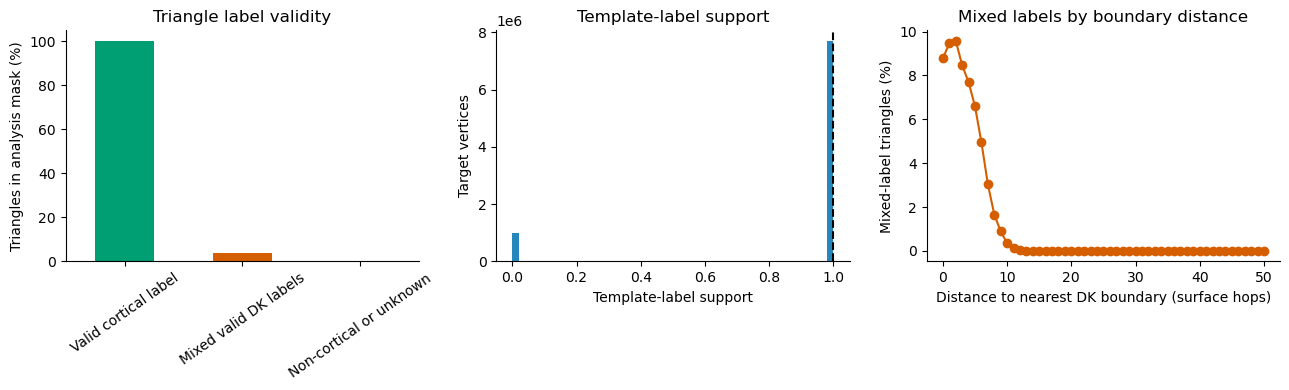

In [7]:
pooled_counts = pd.Series(
    {
        "Valid cortical label": weighted_valid,
        "Mixed valid DK labels": weighted_mixed,
        "Non-cortical or unknown": weighted_noncortical,
    }
)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
pooled_counts.plot.bar(ax=axes[0], color=["#009E73", "#D55E00", "#CC79A7"])
axes[0].set_ylabel("Triangles in analysis mask (%)")
axes[0].set_title("Triangle label validity")
axes[0].tick_params(axis="x", rotation=35)
axes[1].hist(support_values, bins=50, color="#0072B2", alpha=0.85)
axes[1].axvline(np.nanmedian(support_values), color="black", linestyle="--")
axes[1].set_xlabel("Template-label support")
axes[1].set_ylabel("Target vertices")
axes[1].set_title("Template-label support")
boundary_plot = boundary_summary.copy()
boundary_plot["mixed_pct"] = (
    boundary_plot.n_mixed_valid_label_triangles
    / boundary_plot.n_valid_label_triangles
    * 100
)
boundary_curve = boundary_plot.groupby("boundary_hops").mixed_pct.median()
axes[2].plot(boundary_curve.index, boundary_curve.values, marker="o", color="#D55E00")
axes[2].set_xlabel("Distance to nearest DK boundary (surface hops)")
axes[2].set_ylabel("Mixed-label triangles (%)")
axes[2].set_title("Mixed labels by boundary distance")
for axis in axes:
    axis.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
label_figure_path = FIGURE_ROOT / "10_label_sampling_qc_summary.png"
fig.savefig(label_figure_path, dpi=300, bbox_inches="tight")
plt.show()

In [8]:
case_table = label_summary.sort_values("mixed_valid_label_pct")
normal_case = case_table.iloc[0]
mixed_case = case_table.iloc[-1]
LABEL_CASE_ROOT = OUTPUT_ROOT / "label_qc_cases"
LABEL_CASE_ROOT.mkdir(parents=True, exist_ok=True)

def write_ascii_label(path, vertex_ids, coordinates):
    vertex_ids = np.asarray(vertex_ids, dtype=int)
    coordinates = np.asarray(coordinates, dtype=float)
    lines = ["#!ascii label", "# Source triangle vertices for label-sampling QC", str(len(vertex_ids))]
    lines.extend(
        f"{vertex_id:d} {xyz[0]:.6f} {xyz[1]:.6f} {xyz[2]:.6f} 1.000000"
        for vertex_id, xyz in zip(vertex_ids, coordinates)
    )
    path.write_text("\n".join(lines) + "\n")

def export_label_case(case, case_name, max_targets=100):
    subject = str(case.subject)
    hemisphere = str(case.hemisphere)
    native_root = Path(manifest.loc[manifest.subject_id.eq(subject), "subjects_dir"].iloc[0]) / subject
    profile_path = (
        O3_ROOT / subject / "fsaverage" / "o3_coordinate"
        / f"{subject}_{hemisphere}_profiles.npz"
    )
    with np.load(profile_path, allow_pickle=True) as data:
        bundle = {key: data[key] for key in data.files}
    target_ids = np.asarray(bundle["target_vertex_id"], dtype=int)
    source_ids = np.asarray(bundle["source_vertex_ids"], dtype=int)
    weights = np.asarray(bundle["barycentric_weights"], dtype=float)
    mapping_valid = np.asarray(bundle["mapping_valid"], dtype=bool)
    sphere, faces = nib.freesurfer.io.read_geometry(
        str(native_root / "surf" / f"{hemisphere}.sphere.reg")
    )
    native_labels, native_names, _ = load_analysis_mask(
        native_root / "label" / f"{hemisphere}.aparc.annot",
        native_root / "label" / f"{hemisphere}.cortex.label",
    )
    template_labels, template_names, template_mask = load_analysis_mask(
        FS_SUBJECTS_DIR / "fsaverage" / "label" / f"{hemisphere}.aparc.annot",
        FS_SUBJECTS_DIR / "fsaverage" / "label" / f"{hemisphere}.cortex.label",
    )
    in_mask = template_mask[target_ids]
    source_in_range = np.all((source_ids >= 0) & (source_ids < len(sphere)), axis=1)
    face_ids = np.asarray(bundle["source_face_id"], dtype=int)
    face_in_range = (face_ids >= 0) & (face_ids < len(faces))
    face_match = np.zeros(len(target_ids), dtype=bool)
    valid_rows = source_in_range & face_in_range
    face_match[valid_rows] = np.all(
        faces[face_ids[valid_rows]] == source_ids[valid_rows], axis=1
    )
    weights_valid = (
        np.isfinite(weights).all(axis=1)
        & (np.abs(weights.sum(axis=1) - 1) <= 1e-6)
        & (weights >= -1e-6).all(axis=1)
        & (weights <= 1 + 1e-6).all(axis=1)
    )
    strict = mapping_valid & valid_rows & face_match & weights_valid & in_mask
    source_label_values = np.full(source_ids.shape, -1, dtype=int)
    source_label_values[source_in_range] = native_labels[source_ids[source_in_range]]
    native_valid_code = np.array(
        [name.lower().replace("-", "_") not in EXCLUDED_LABELS for name in native_names],
        dtype=bool,
    )
    all_valid = np.zeros(len(target_ids), dtype=bool)
    all_valid[strict] = native_valid_code[source_label_values[strict]].all(axis=1)
    mixed = all_valid & (
        (source_label_values[:, 0] != source_label_values[:, 1])
        | (source_label_values[:, 1] != source_label_values[:, 2])
    )
    if case_name == "normal":
        selected = np.flatnonzero(all_valid & ~mixed)[:max_targets]
    else:
        selected = np.flatnonzero(mixed)[:max_targets]
    if len(selected) == 0:
        selected = np.flatnonzero(strict)[:max_targets]
    selected_source_ids = np.unique(source_ids[selected].reshape(-1))
    label_path = LABEL_CASE_ROOT / f"{case_name}_{subject}_{hemisphere}_source_triangles.label"
    write_ascii_label(label_path, selected_source_ids, sphere[selected_source_ids])
    selected_table = pd.DataFrame(
        {
            "target_vertex_id": target_ids[selected],
            "source_face_id": face_ids[selected],
            "source_vertex_1": source_ids[selected, 0],
            "source_vertex_2": source_ids[selected, 1],
            "source_vertex_3": source_ids[selected, 2],
            "weight_1": weights[selected, 0],
            "weight_2": weights[selected, 1],
            "weight_3": weights[selected, 2],
            "native_label_1": [native_names[value] for value in source_label_values[selected, 0]],
            "native_label_2": [native_names[value] for value in source_label_values[selected, 1]],
            "native_label_3": [native_names[value] for value in source_label_values[selected, 2]],
            "template_label": [template_names[value] for value in template_labels[target_ids[selected]]],
            "mixed_valid_label": mixed[selected],
        }
    )
    csv_path = LABEL_CASE_ROOT / f"{case_name}_{subject}_{hemisphere}_triangles.csv"
    selected_table.to_csv(csv_path, index=False)
    surface_path = native_root / "surf" / f"{hemisphere}.white"
    annotation_path = native_root / "label" / f"{hemisphere}.aparc.annot"
    freeview_command = (
        f"freeview -f {surface_path}:annot={annotation_path}:label={label_path}"
    )
    return {
        "case": case_name,
        "subject": subject,
        "hemisphere": hemisphere,
        "n_selected_target_vertices": len(selected),
        "n_selected_source_vertices": len(selected_source_ids),
        "label_file": str(label_path),
        "triangle_table": str(csv_path),
        "freeview_command": freeview_command,
    }

case_exports = pd.DataFrame(
    [
        export_label_case(normal_case, "normal"),
        export_label_case(mixed_case, "mixed"),
    ]
)
case_exports.to_csv(TABLE_ROOT / "label_visual_check_cases.csv", index=False)
display_cases = case_table.loc[
    case_table.subject.isin([normal_case.subject, mixed_case.subject])
    & case_table.hemisphere.isin([normal_case.hemisphere, mixed_case.hemisphere])
]
display(display_cases[["subject", "hemisphere", "mixed_valid_label_pct"]])
display(case_exports)
print("The label files contain source vertices from the selected mapped triangles.")
print("Use each printed Freeview command to inspect the native white surface, DK annotation, and sampled triangles.")

,subject,hemisphere,mixed_valid_label_pct
39,D0321,rh,3.400344
38,D0321,lh,3.483091
19,D0151,rh,4.056001
18,D0151,lh,4.120624


,case,subject,hemisphere,n_selected_target_vertices,n_selected_source_vertices,label_file,triangle_table,freeview_command
0,normal,D0321,rh,100,300,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/results/...,freeview -f /mnt/newStor/paros/paros_WORK/xint...
1,mixed,D0151,lh,100,300,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/results/...,freeview -f /mnt/newStor/paros/paros_WORK/xint...


The label files contain source vertices from the selected mapped triangles.
Use each printed Freeview command to inspect the native white surface, DK annotation, and sampled triangles.


## 5. Additional subject-level diagnostics

These supplementary figures show vertex-level flag distributions and standardized subject-by-hemisphere QC metrics. They are kept separate from the primary coverage, sampling, and label analyses.

05_flag_frequency_distributions.png


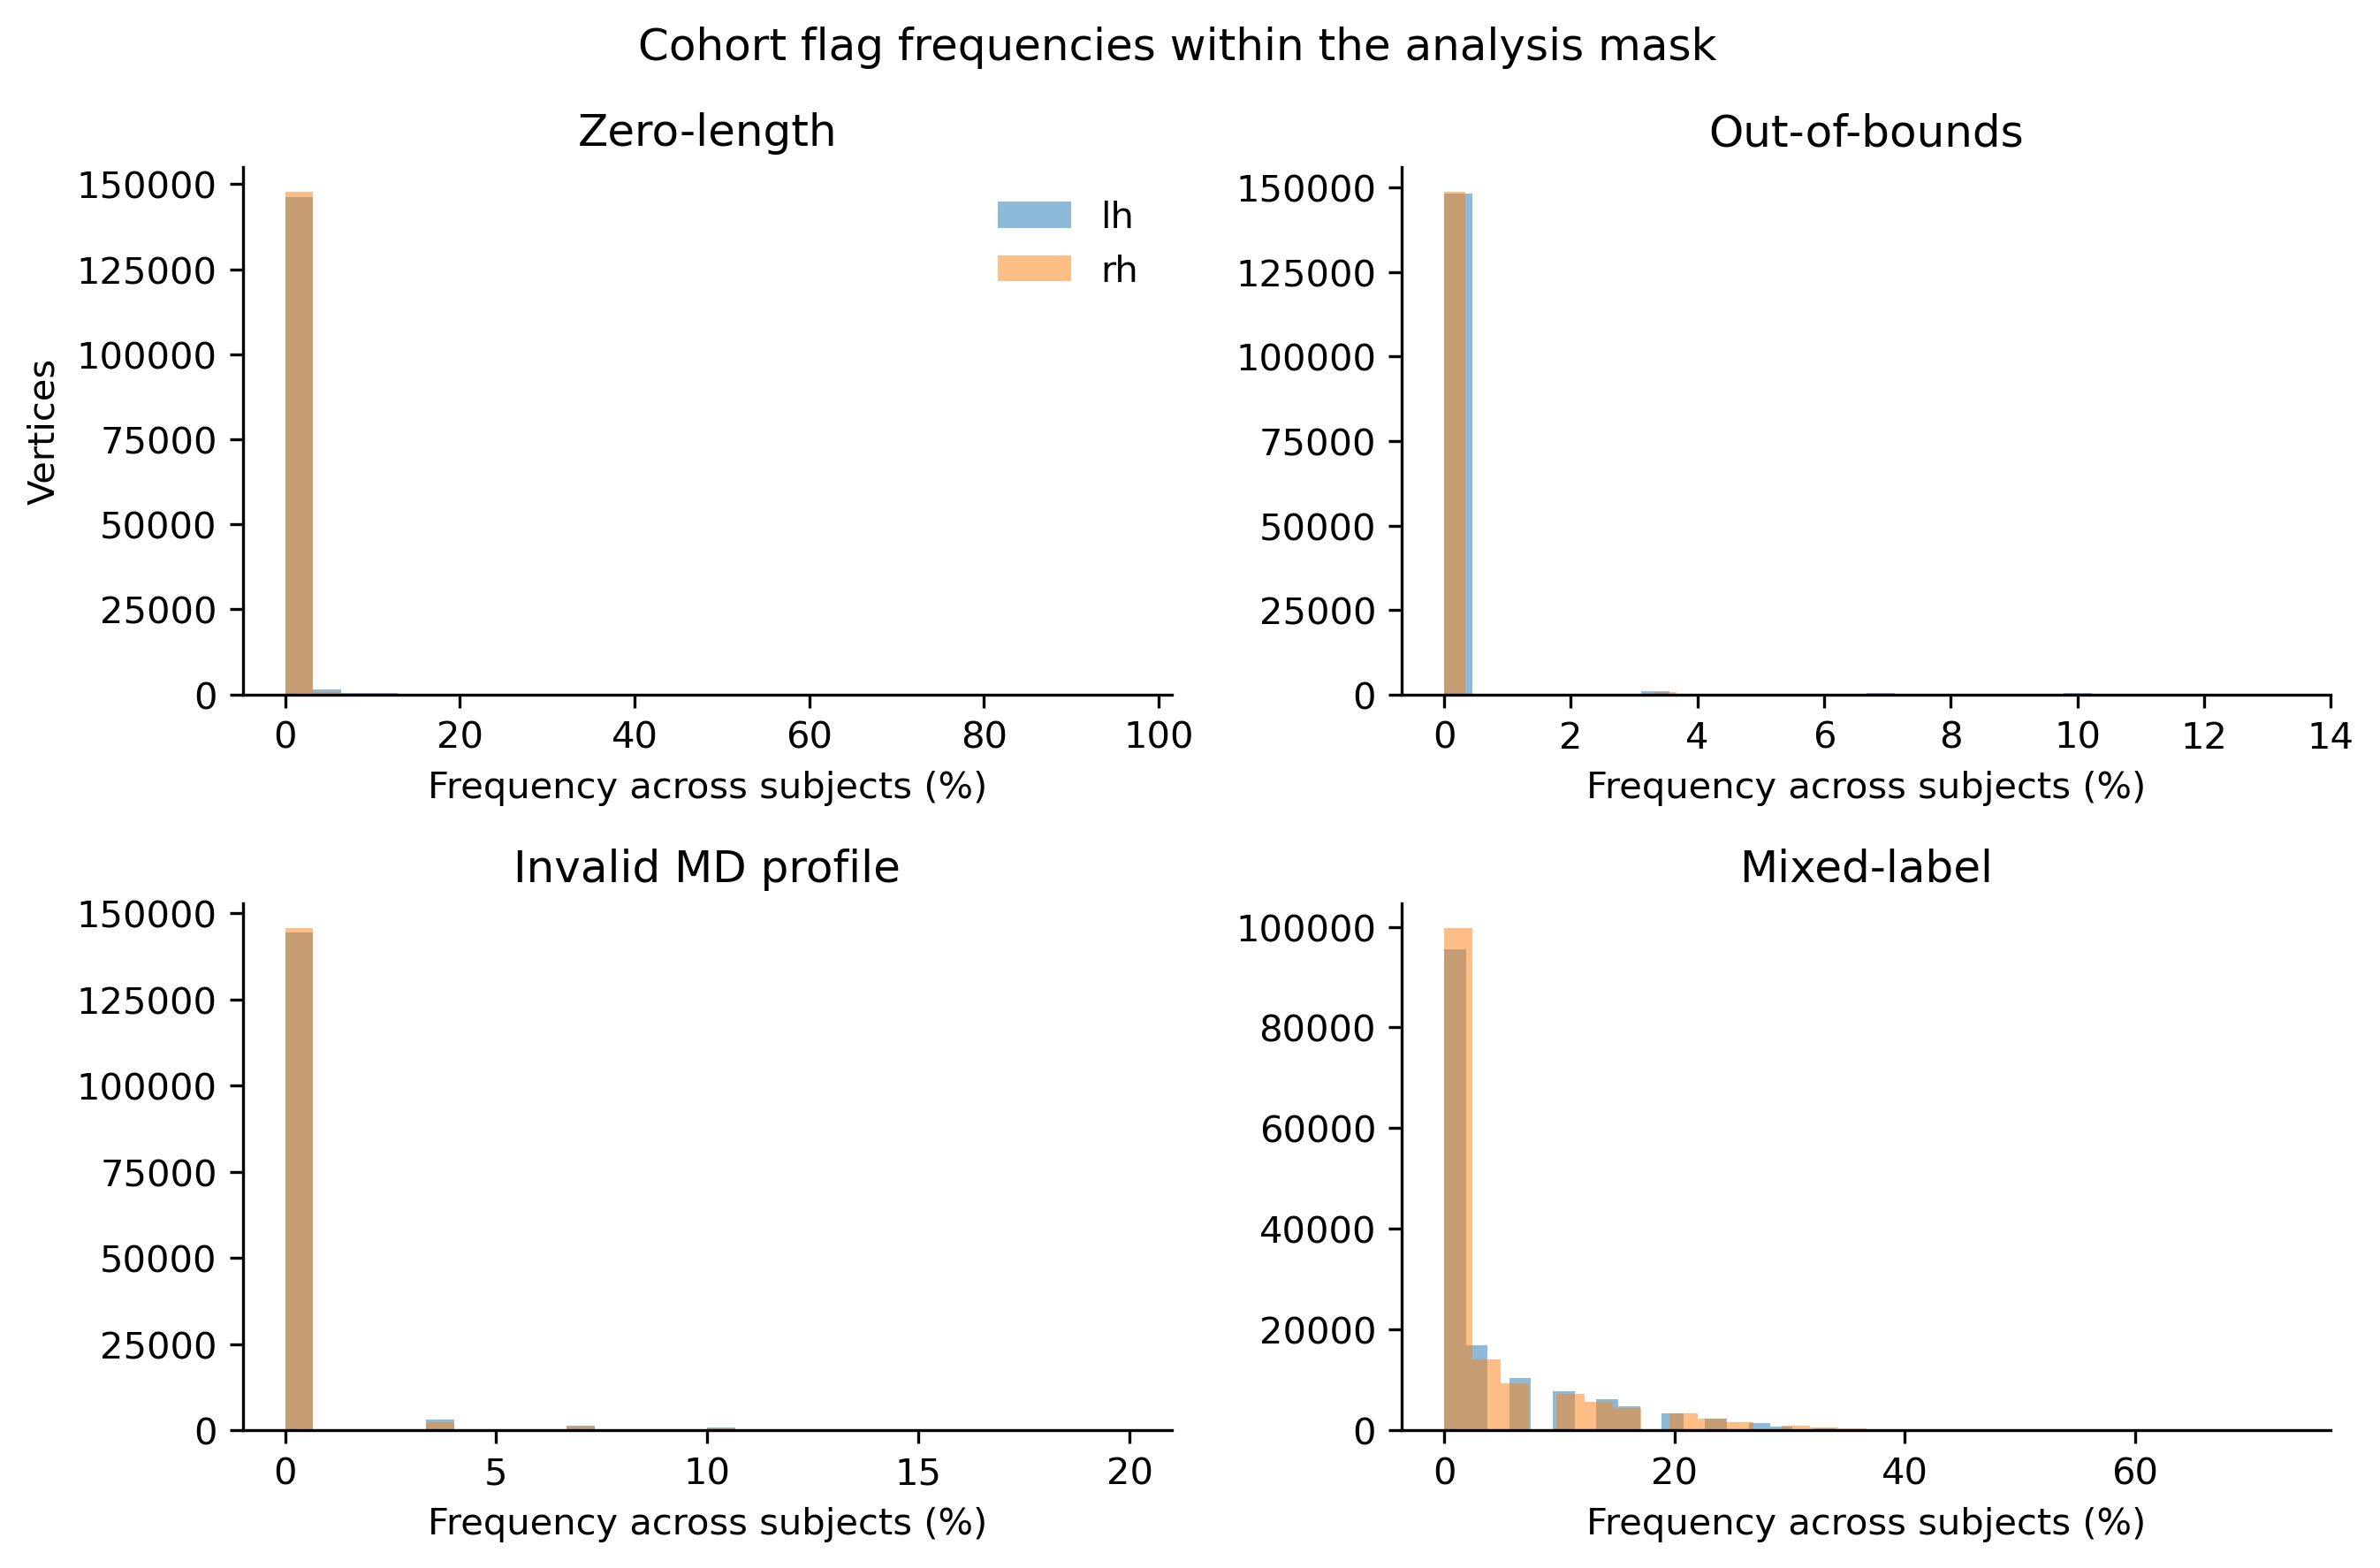

06_subject_qc_heatmap.png


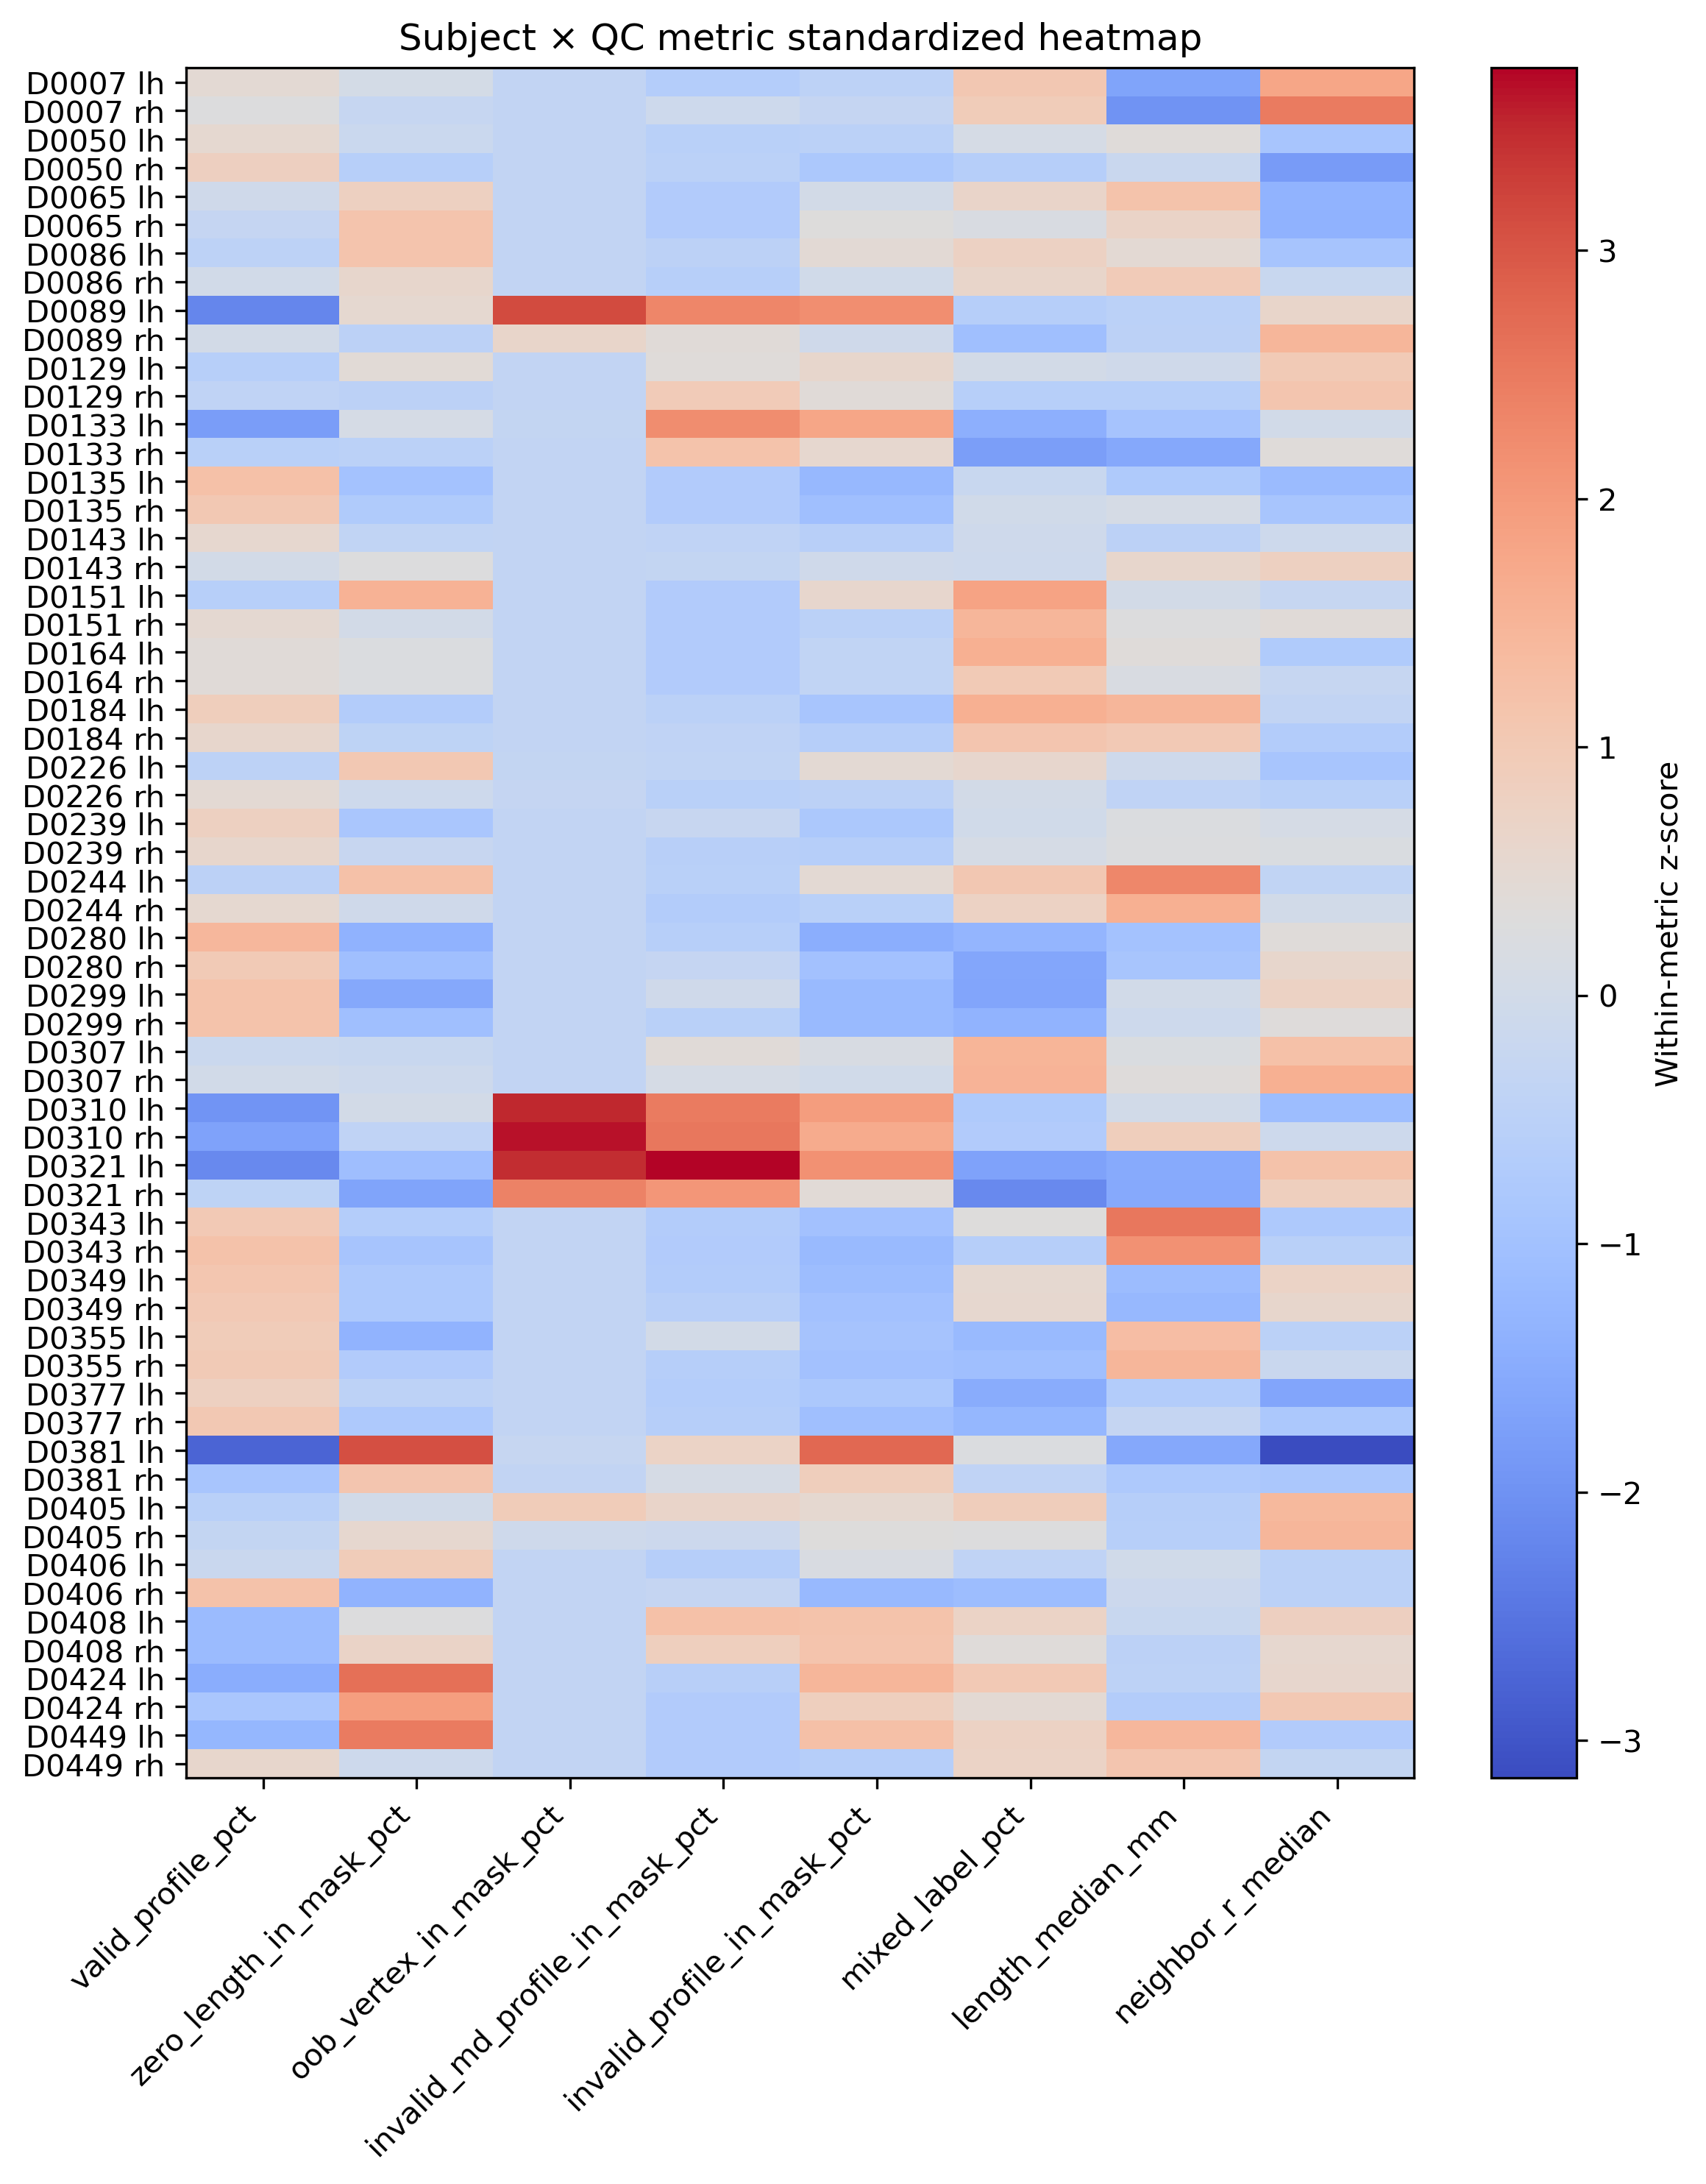

In [9]:
for figure_name in [
    "05_flag_frequency_distributions.png",
    "06_subject_qc_heatmap.png",
]:
    print(figure_name)
    display(Image(filename=str(FIGURE_ROOT / figure_name)))